## <center>**KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**</center>
### <center>**Prompt AI Dan Penyelesaian Masalah Geofisika**</center>
#### **NAMA**   : **Rahmat Hidayat**
#### **NIM**    : **(H061231087)**
#### **KELAS** : **B**
<hr>

### ***KASUS/PROMPT 1 : PENGOLAHAN DATA SEISMIK REFRAKSI***

#### ***Struktur Prompt***

Judul: Analisis Data Seismik Refraksi untuk Identifikasi Litologi Bawah Permukaan

Bertindaklah sebagai ahli geofisika terapan dan dosen pembimbing praktikum Geofisika yang memiliki keahlian dalam metode seismik refraksi. Lakukan analisis data seismik refraksi menggunakan data waktu tempuh gelombang P (first arrival time) terhadap jarak geofon untuk mengidentifikasi kecepatan gelombang seismik, kedalaman lapisan, serta kondisi litologi bawah permukaan. Gunakan metode Time-Distance Curve dan analisis Intercept Time untuk menentukan parameter lapisan bawah permukaan. Sajikan tahapan pengolahan data secara sistematis, perhitungan matematis, kode Python, grafik, serta interpretasi geologi berdasarkan hasil analisis.


WAKTU INTERSEP TEORITIS
ti lapisan 2 = 0.010392 s
ti lapisan 3 = 0.019090 s

CONTOH DATA SIMULASI
arah_shot  geofon  posisi_geofon_m  jarak_dari_sumber_m  first_arrival_s  cabang_teori
  Forward       1              0.0                  0.0         0.000024             1
  Forward       2              2.0                  2.0         0.003917             1
  Forward       3              4.0                  4.0         0.008060             1
  Forward       4              6.0                  6.0         0.012075             1
  Forward       5              8.0                  8.0         0.015844             1
  Forward       6             10.0                 10.0         0.019896             1
  Forward       7             12.0                 12.0         0.022403             2
  Forward       8             14.0                 14.0         0.024367             2
  Forward       9             16.0                 16.0         0.025488             3
  Forward      10             18

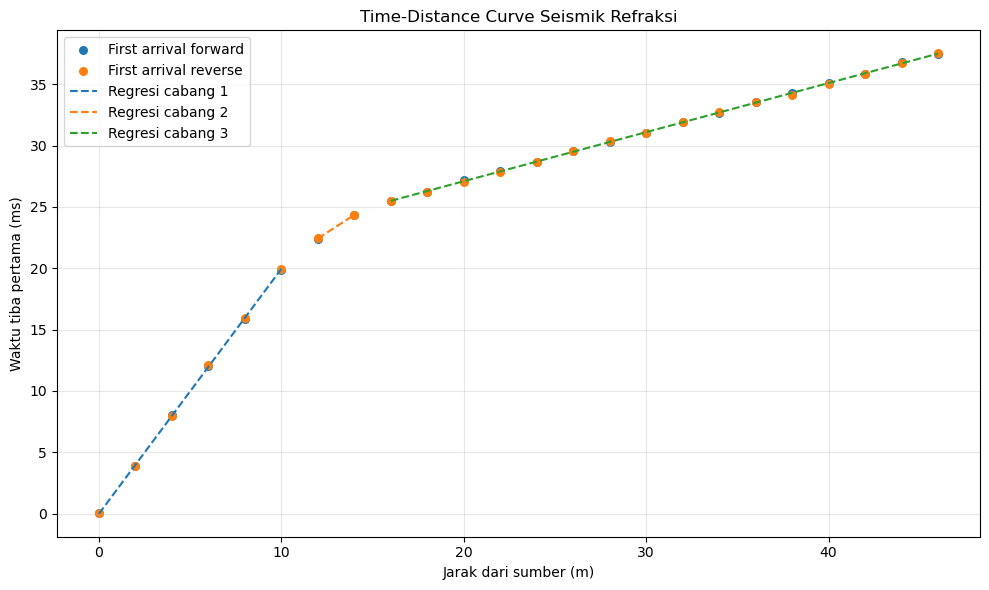

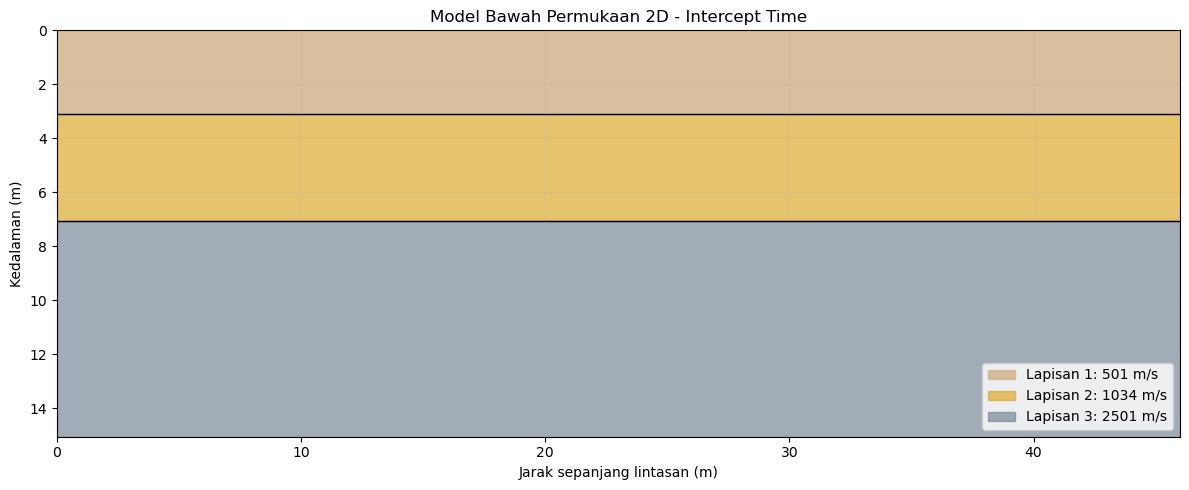


INTERPRETASI AWAL
Lapisan 1: Vp = 501.2 m/s -> Tanah lepas atau material lapuk; perlu verifikasi
Lapisan 2: Vp = 1034.0 m/s -> Tanah padat atau sedimen; perlu verifikasi
Lapisan 3: Vp = 2500.9 m/s -> Material terkonsolidasi atau batuan lapuk

Catatan: litologi tidak dapat ditentukan hanya dari kecepatan. Cocokkan dengan data geologi setempat.


In [1]:

# ============================================================
# ANALISIS DATA SEISMIK REFRAKSI - METODE INTERCEPT TIME
# Data simulasi: 24 geofon, 3 lapisan, forward dan reverse shot
# Satuan: jarak (m), waktu (s), kecepatan (m/s), kedalaman (m)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ------------------------------------------------------------
# 1. PARAMETER DATA SIMULASI
# ------------------------------------------------------------

n_geofon = 24
spasi_geofon = 2.0

# Posisi geofon dalam satu lintasan
x_geofon = np.arange(n_geofon) * spasi_geofon
panjang_lintasan = x_geofon[-1]

# Parameter model simulasi (bukan hasil pengukuran lapangan)
V_model = np.array([500.0, 1000.0, 2500.0])
h_model = np.array([3.0, 4.0])  # ketebalan lapisan 1 dan 2

V1, V2, V3 = V_model
h1_model, h2_model = h_model

# ------------------------------------------------------------
# 2. MENGHITUNG WAKTU INTERSEP TEORITIS
# ------------------------------------------------------------

ti2_model = (
    2 * h1_model * np.sqrt(V2**2 - V1**2) / (V1 * V2)
)

ti3_model = (
    2 * h1_model * np.sqrt(V3**2 - V1**2) / (V1 * V3)
    + 2 * h2_model * np.sqrt(V3**2 - V2**2) / (V2 * V3)
)

print("WAKTU INTERSEP TEORITIS")
print(f"ti lapisan 2 = {ti2_model:.6f} s")
print(f"ti lapisan 3 = {ti3_model:.6f} s")

# ------------------------------------------------------------
# 3. MEMBUAT DATA FIRST ARRIVAL SIMULASI
# ------------------------------------------------------------

# Tiga cabang kurva waktu tempuh:
# cabang 0 = gelombang langsung pada lapisan 1
# cabang 1 = gelombang refraksi pada lapisan 2
# cabang 2 = gelombang refraksi pada lapisan 3

def hitung_cabang(x):
    return np.column_stack([
        x / V1,
        ti2_model + x / V2,
        ti3_model + x / V3
    ])

data = []

for arah in ["Forward", "Reverse"]:
    # Jarak dari sumber untuk masing-masing arah
    if arah == "Forward":
        jarak = x_geofon.copy()
    else:
        jarak = panjang_lintasan - x_geofon

    cabang = hitung_cabang(jarak)

    # First arrival adalah waktu tempuh terkecil
    indeks_cabang = np.argmin(cabang, axis=1)
    waktu_teori = np.min(cabang, axis=1)

    # Noise kecil untuk membuat simulasi lebih realistis
    # Seed tetap agar hasil selalu sama saat dijalankan
    rng = np.random.default_rng(
        42 if arah == "Forward" else 43
    )
    noise = rng.normal(0, 0.00008, size=n_geofon)

    waktu_observasi = np.maximum(waktu_teori + noise, 0)

    for i in range(n_geofon):
        data.append({
            "arah_shot": arah,
            "geofon": i + 1,
            "posisi_geofon_m": x_geofon[i],
            "jarak_dari_sumber_m": jarak[i],
            "first_arrival_s": waktu_observasi[i],
            "cabang_teori": indeks_cabang[i] + 1
        })

df = pd.DataFrame(data)

print("\nCONTOH DATA SIMULASI")
print(df.head(10).round(6).to_string(index=False))

# Simpan data simulasi ke CSV
df.to_csv("data_refraksi_simulasi.csv", index=False)
print("\nData tersimpan: data_refraksi_simulasi.csv")

# ------------------------------------------------------------
# 4. REGRESI LINIER TIME-DISTANCE
# ------------------------------------------------------------

# t = intercept + slope * x
# V = 1 / slope
# Hanya gunakan data yang berada pada cabang first arrival
# yang sama menurut model simulasi.

hasil = []

for cabang_id in [1, 2, 3]:
    subset = df[df["cabang_teori"] == cabang_id]

    if len(subset) < 3:
        print(f"Peringatan: cabang {cabang_id} "
              "memiliki data terlalu sedikit.")
        continue

    regresi = linregress(
        subset["jarak_dari_sumber_m"],
        subset["first_arrival_s"]
    )

    slope = regresi.slope
    intercept = regresi.intercept

    if slope <= 0:
        raise ValueError("Slope tidak positif; periksa data.")

    kecepatan = 1 / slope

    hasil.append({
        "cabang": cabang_id,
        "jumlah_data": len(subset),
        "slope_s_per_m": slope,
        "intercept_s": intercept,
        "kecepatan_m_per_s": kecepatan,
        "R2": regresi.rvalue**2
    })

hasil_df = pd.DataFrame(hasil)

print("\nHASIL REGRESI TIME-DISTANCE")
print(hasil_df.round(5).to_string(index=False))

# ------------------------------------------------------------
# 5. ESTIMASI KEDALAMAN DENGAN INTERCEPT TIME
# ------------------------------------------------------------

# Kecepatan dari hasil regresi
# Cabang 1: lapisan pertama
# Cabang 2: lapisan kedua
# Cabang 3: lapisan ketiga

if not all(c in hasil_df["cabang"].values for c in [1, 2, 3]):
    raise ValueError(
        "Salah satu cabang tidak terdeteksi. "
        "Periksa rentang jarak atau parameter model."
    )

def ambil_hasil(cabang, kolom):
    return hasil_df.loc[
        hasil_df["cabang"] == cabang, kolom
    ].iloc[0]

V1_est = ambil_hasil(1, "kecepatan_m_per_s")
V2_est = ambil_hasil(2, "kecepatan_m_per_s")
V3_est = ambil_hasil(3, "kecepatan_m_per_s")

ti2_est = ambil_hasil(2, "intercept_s")
ti3_est = ambil_hasil(3, "intercept_s")

if not (0 < V1_est < V2_est < V3_est):
    raise ValueError(
        "Kecepatan tidak memenuhi V1 < V2 < V3. "
        "Periksa pemilihan cabang dan kualitas data."
    )

# Kedalaman batas lapisan 1-2
h1_est = (
    ti2_est * V1_est * V2_est
    / (2 * np.sqrt(V2_est**2 - V1_est**2))
)

# Kontribusi lapisan pertama pada intercept lapisan ketiga
ti3_kontribusi_h1 = (
    2 * h1_est * np.sqrt(V3_est**2 - V1_est**2)
    / (V1_est * V3_est)
)

# Kedalaman/ketebalan lapisan 2
penyebut_h2 = (
    2 * np.sqrt(V3_est**2 - V2_est**2)
    / (V2_est * V3_est)
)

h2_est = (ti3_est - ti3_kontribusi_h1) / penyebut_h2

if h1_est <= 0 or h2_est <= 0:
    raise ValueError(
        "Kedalaman tidak positif. Model tidak konsisten "
        "dengan waktu intersep hasil regresi."
    )

kedalaman_batas_12 = h1_est
kedalaman_batas_23 = h1_est + h2_est

ringkasan = pd.DataFrame({
    "Parameter": [
        "Kecepatan lapisan 1",
        "Kecepatan lapisan 2",
        "Kecepatan lapisan 3",
        "Waktu intersep lapisan 2",
        "Waktu intersep lapisan 3",
        "Ketebalan lapisan 1",
        "Ketebalan lapisan 2",
        "Kedalaman batas 1-2",
        "Kedalaman batas 2-3"
    ],
    "Nilai": [
        V1_est, V2_est, V3_est,
        ti2_est, ti3_est,
        h1_est, h2_est,
        kedalaman_batas_12,
        kedalaman_batas_23
    ],
    "Satuan": [
        "m/s", "m/s", "m/s", "s", "s",
        "m", "m", "m", "m"
    ]
})

print("\nRINGKASAN HASIL ESTIMASI")
print(ringkasan.round(4).to_string(index=False))

# ------------------------------------------------------------
# 6. GRAFIK TIME-DISTANCE CURVE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

warna = {"Forward": "tab:blue", "Reverse": "tab:orange"}

for arah in ["Forward", "Reverse"]:
    sub = df[df["arah_shot"] == arah].sort_values(
        "jarak_dari_sumber_m"
    )
    ax.scatter(
        sub["jarak_dari_sumber_m"],
        sub["first_arrival_s"] * 1000,
        label=f"First arrival {arah.lower()}",
        color=warna[arah],
        s=30
    )

# Tambahkan garis regresi setiap cabang
for _, baris in hasil_df.iterrows():
    cabang_id = int(baris["cabang"])
    sub = df[df["cabang_teori"] == cabang_id]

    x_fit = np.linspace(
        sub["jarak_dari_sumber_m"].min(),
        sub["jarak_dari_sumber_m"].max(),
        100
    )

    t_fit = (
        baris["intercept_s"]
        + baris["slope_s_per_m"] * x_fit
    )

    ax.plot(
        x_fit, t_fit * 1000,
        linestyle="--",
        label=f"Regresi cabang {cabang_id}"
    )

ax.set_title("Time-Distance Curve Seismik Refraksi")
ax.set_xlabel("Jarak dari sumber (m)")
ax.set_ylabel("Waktu tiba pertama (ms)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. PENAMPANG MODEL BAWAH PERMUKAAN 2D
# ------------------------------------------------------------

x_model = np.linspace(0, panjang_lintasan, 250)

# Batas lapisan horizontal berdasarkan estimasi
z12 = h1_est
z23 = h1_est + h2_est
zmax = z23 + 8  # tambahan kedalaman untuk visualisasi

fig, ax = plt.subplots(figsize=(12, 5))

ax.fill_between(
    x_model, 0, z12,
    color="tan", alpha=0.85,
    label=f"Lapisan 1: {V1_est:.0f} m/s"
)
ax.fill_between(
    x_model, z12, z23,
    color="goldenrod", alpha=0.65,
    label=f"Lapisan 2: {V2_est:.0f} m/s"
)
ax.fill_between(
    x_model, z23, zmax,
    color="slategray", alpha=0.65,
    label=f"Lapisan 3: {V3_est:.0f} m/s"
)

ax.axhline(z12, color="black", linewidth=1)
ax.axhline(z23, color="black", linewidth=1)

ax.set_xlim(0, panjang_lintasan)
ax.set_ylim(zmax, 0)
ax.set_xlabel("Jarak sepanjang lintasan (m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Model Bawah Permukaan 2D - Intercept Time")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. INTERPRETASI AWAL KECEPATAN
# ------------------------------------------------------------

def interpretasi_litologi(V):
    if V < 600:
        return "Tanah lepas atau material lapuk; perlu verifikasi"
    elif V < 1500:
        return "Tanah padat atau sedimen; perlu verifikasi"
    elif V < 3000:
        return "Material terkonsolidasi atau batuan lapuk"
    else:
        return "Batuan lebih kompak mungkin; perlu verifikasi"

print("\nINTERPRETASI AWAL")
for i, V in enumerate([V1_est, V2_est, V3_est], start=1):
    print(
        f"Lapisan {i}: Vp = {V:.1f} m/s -> "
        f"{interpretasi_litologi(V)}"
    )

print("\nCatatan: litologi tidak dapat ditentukan hanya "
      "dari kecepatan. Cocokkan dengan data geologi setempat.")



### Interpretasi Penampang Seismik Refraksi 2D

1. **Lapisan 1 (\(V_p \approx 500\ \text{m/s}\)):**  
   Kecepatan gelombang relatif rendah \(\rightarrow\) diinterpretasikan sebagai tanah lepas atau material lapuk di dekat permukaan.

2. **Lapisan 2 (\(V_p \approx 1.000\ \text{m/s}\)):**  
   Kecepatan gelombang lebih tinggi dibandingkan lapisan pertama \(\rightarrow\) diperkirakan sebagai sedimen yang lebih padat atau material terkonsolidasi.

3. **Lapisan 3 (\(V_p \approx 2.500\ \text{m/s}\)):**  
   Kecepatan gelombang relatif tinggi \(\rightarrow\) diinterpretasikan sebagai material kompak atau batuan lapuk hingga batuan dasar.

4. **Batas Lapisan 1–2 (Kedalaman \(\approx 3\ \text{m}\)):**  
   Perubahan kecepatan gelombang menunjukkan batas antara material permukaan yang lebih lunak dan lapisan di bawahnya.

5. **Batas Lapisan 2–3 (Kedalaman \(\approx 7\ \text{m}\)):**  
   Peningkatan kecepatan gelombang menunjukkan perubahan sifat fisik material menuju lapisan yang lebih kompak.

### Kesimpulan

Penampang seismik refraksi 2D menunjukkan model bawah permukaan yang terdiri atas tiga lapisan dengan kecepatan gelombang yang meningkat terhadap kedalaman. Lapisan teratas diperkirakan berupa material lepas atau lapuk, sedangkan lapisan terdalam berpotensi berupa material yang lebih kompak. Interpretasi litologi bersifat sementara karena menggunakan data simulasi dan belum didukung informasi geologi atau data pengeboran.


--------------------------------------------------
### ***PROMPT 2 : PENGOLAHAN DATA GEOLISTRIK RESISTIVITAS***

#### ***Struktur Prompt***

Judul: Analisis Data Geolistrik Resistivitas untuk Identifikasi Litologi dan Akuifer Bawah Permukaan

Bertindaklah sebagai ahli geofisika terapan dan dosen pembimbing yang memiliki keahlian dalam metode geolistrik resistivitas. Lakukan pengolahan dan analisis data geolistrik menggunakan konfigurasi Schlumberger atau Wenner untuk mengidentifikasi distribusi resistivitas bawah permukaan, memperkirakan kedalaman lapisan, serta menginterpretasikan kondisi geologi dan potensi akuifer. Gunakan metode inversi 1D atau 2D sesuai dengan jenis data yang tersedia. Sajikan tahapan pengolahan data secara sistematis, perhitungan matematis, kode Python, grafik, serta interpretasi geologi berdasarkan hasil analisis.



MODEL SIMULASI AWAL
Resistivitas lapisan 1 = 100.0 ohm m
Resistivitas lapisan 2 = 20.0 ohm m
Resistivitas lapisan 3 = 150.0 ohm m
Ketebalan lapisan 1 = 3.0 m
Ketebalan lapisan 2 = 7.0 m

TABEL DATA GEOLISTRIK SIMULASI
 AB/2_m  MN/2_m  AB_m  MN_m  Arus_mA  Beda_potensial_mV  Faktor_geometri_m  Resistivitas_semu_ohm_m
    1.0     0.5   2.0   1.0    100.0           3951.884              2.356                   93.114
    1.5     0.5   3.0   1.0    100.0           1358.880              6.283                   85.381
    2.0     0.5   4.0   1.0    100.0            694.973             11.781                   81.875
    3.0     0.5   6.0   1.0    100.0            276.413             27.489                   75.983
    4.0     0.5   8.0   1.0    100.0            138.420             49.480                   68.491
    6.0     0.5  12.0   1.0    100.0             60.972            112.312                   68.479
    8.0     0.5  16.0   1.0    100.0             38.538            200.277        

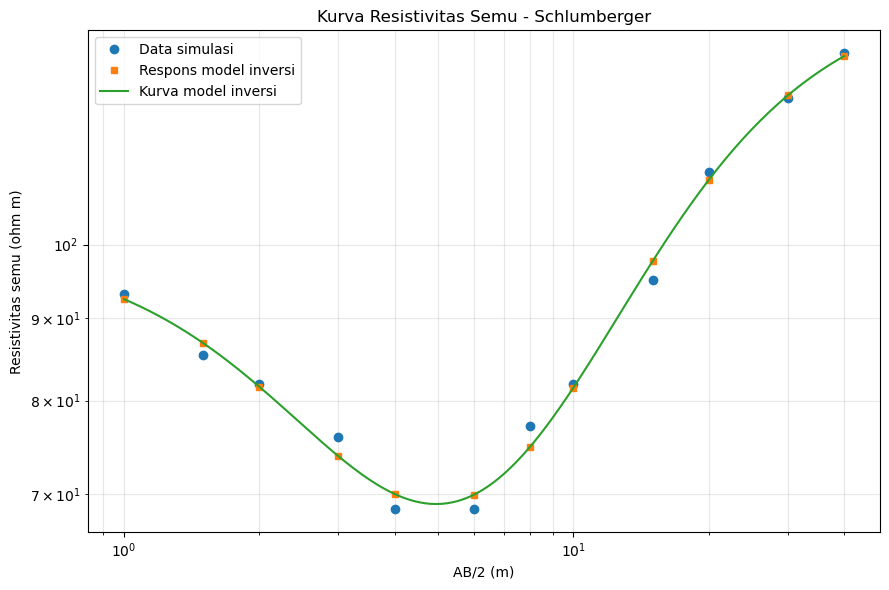

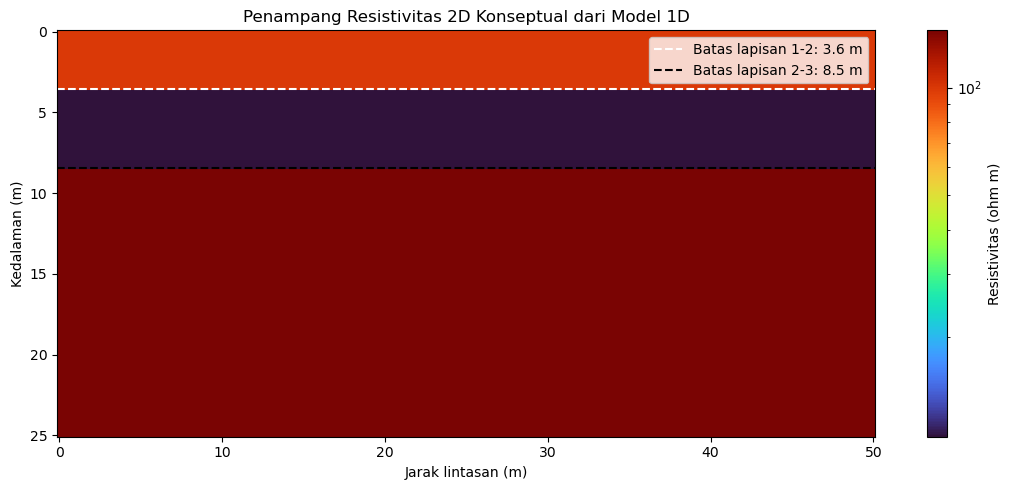


INTERPRETASI AWAL MODEL
Lapisan 1: 99.93 ohm m -> Resistivitas menengah; sedimen atau material lapuk
Lapisan 2: 10.54 ohm m -> Konduktif; lempung atau sedimen jenuh air mungkin
Lapisan 3: 144.59 ohm m -> Relatif resistif; pasir, kerikil, atau batuan mungkin

Catatan:
- Data ini merupakan simulasi, bukan pengukuran lapangan.
- Inversi menggunakan respons pendekatan untuk pembelajaran.
- Interpretasi akuifer harus didukung data geologi/hidrogeologi.


In [4]:

# ============================================================
# PENGOLAHAN DATA GEOLISTRIK RESISTIVITAS
# Konfigurasi Schlumberger - Data Simulasi
# Model 1D tiga lapisan + visualisasi penampang 2D konseptual
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

np.random.seed(42)

# ------------------------------------------------------------
# 1. PARAMETER SURVEI DAN MODEL SIMULASI
# ------------------------------------------------------------

I_mA = 100.0                  # Arus dalam mA
I = I_mA / 1000.0             # Konversi ke ampere

# Setengah jarak elektroda arus AB/2 (m)
AB2 = np.array([1, 1.5, 2, 3, 4, 6, 8, 10, 15, 20, 30, 40],
               dtype=float)

# Setengah jarak elektroda potensial MN/2 (m)
# MN dibuat lebih kecil dari AB untuk konfigurasi Schlumberger
MN2 = np.where(AB2 <= 10, 0.5, 1.0)

# Parameter model simulasi (nilai sebenarnya diketahui)
rho_model = np.array([100.0, 20.0, 150.0])  # ohm m
h_model = np.array([3.0, 7.0])              # meter

print("MODEL SIMULASI AWAL")
print(f"Resistivitas lapisan 1 = {rho_model[0]} ohm m")
print(f"Resistivitas lapisan 2 = {rho_model[1]} ohm m")
print(f"Resistivitas lapisan 3 = {rho_model[2]} ohm m")
print(f"Ketebalan lapisan 1 = {h_model[0]} m")
print(f"Ketebalan lapisan 2 = {h_model[1]} m")

# ------------------------------------------------------------
# 2. FAKTOR GEOMETRI SCHLUMBERGER
# ------------------------------------------------------------

# AB = jarak total elektroda arus
# MN = jarak total elektroda potensial
AB = 2 * AB2
MN = 2 * MN2

K = np.pi * (AB**2 - MN**2) / (4 * MN)

# ------------------------------------------------------------
# 3. MODEL RESPONS SIMULASI
# ------------------------------------------------------------
# Catatan:
# Fungsi di bawah adalah pendekatan transisi sensitivitas
# untuk demonstrasi inversi, BUKAN solver forward Schlumberger
# eksak untuk bumi berlapis.
#
# Parameter resistivitas dan ketebalan diestimasi dengan
# mencocokkan respons pendekatan terhadap data simulasi.

def respons_aproksimasi(log_ab2, params):
    """
    params:
      log10(rho1), log10(rho2), log10(rho3),
      log10(h1), log10(h2)

    Menggunakan transisi halus terhadap skala AB/2.
    """
    rho1, rho2, rho3 = 10 ** params[:3]
    h1, h2 = 10 ** params[3:]

    # Skala kedalaman sensitivitas pendekatan
    z1 = h1
    z2 = h1 + h2

    # Transisi halus dalam domain log10(AB/2)
    q1 = 1 / (1 + np.exp(-4 * (log_ab2 - np.log10(z1 + 0.5))))
    q2 = 1 / (1 + np.exp(-4 * (log_ab2 - np.log10(z2 + 0.5))))

    # Bobot lapisan
    w1 = 1 - q1
    w2 = q1 * (1 - q2)
    w3 = q2

    # Rata-rata geometrik berbobot
    log_rhoa = (
        w1 * np.log(rho1)
        + w2 * np.log(rho2)
        + w3 * np.log(rho3)
    )

    return np.exp(log_rhoa)


# ------------------------------------------------------------
# 4. MEMBUAT DATA RESISTIVITAS SEMU SIMULASI
# ------------------------------------------------------------

# Data sintetis dibuat menggunakan model pendekatan yang sama
parameter_sebenarnya = np.array([
    np.log10(rho_model[0]),
    np.log10(rho_model[1]),
    np.log10(rho_model[2]),
    np.log10(h_model[0]),
    np.log10(h_model[1])
])

rho_a_teori = respons_aproksimasi(
    np.log10(AB2), parameter_sebenarnya
)

# Noise 3% untuk mensimulasikan variasi data
rho_a_obs = rho_a_teori * (
    1 + np.random.normal(0, 0.03, len(AB2))
)

# Beda potensial simulasi dari rho_a = K * DeltaV / I
deltaV = rho_a_obs * I / K
deltaV_mV = deltaV * 1000

# Tabel hasil pengukuran sintetis
df = pd.DataFrame({
    "AB/2_m": AB2,
    "MN/2_m": MN2,
    "AB_m": AB,
    "MN_m": MN,
    "Arus_mA": I_mA,
    "Beda_potensial_mV": deltaV_mV,
    "Faktor_geometri_m": K,
    "Resistivitas_semu_ohm_m": K * (deltaV / I)
})

print("\nTABEL DATA GEOLISTRIK SIMULASI")
print(df.round(3).to_string(index=False))

df.to_csv("data_geolistrik_simulasi.csv", index=False)
print("\nFile disimpan: data_geolistrik_simulasi.csv")

# ------------------------------------------------------------
# 5. INVERSI 1D SEDERHANA MENGGUNAKAN SCIPY
# ------------------------------------------------------------

def residual(params):
    prediksi = respons_aproksimasi(np.log10(AB2), params)

    # Residual logaritmik agar rentang rho besar/kecil seimbang
    return np.log(prediksi) - np.log(rho_a_obs)

# Tebakan awal inversi
tebakan_awal = np.array([
    np.log10(80.0),
    np.log10(40.0),
    np.log10(120.0),
    np.log10(4.0),
    np.log10(5.0)
])

# Batas parameter yang diizinkan
batas_bawah = np.array([
    np.log10(1), np.log10(1), np.log10(1),
    np.log10(0.2), np.log10(0.2)
])

batas_atas = np.array([
    np.log10(2000), np.log10(2000), np.log10(2000),
    np.log10(50), np.log10(100)
])

hasil_inv = least_squares(
    residual,
    tebakan_awal,
    bounds=(batas_bawah, batas_atas),
    max_nfev=10000
)

parameter_inv = 10 ** hasil_inv.x

rho_inv = parameter_inv[:3]
h_inv = parameter_inv[3:]

rho_pred = respons_aproksimasi(
    np.log10(AB2), hasil_inv.x
)

# RMS misfit relatif dalam persen
rms_log = np.sqrt(np.mean(
    (np.log(rho_pred) - np.log(rho_a_obs))**2
))
misfit_persen = 100 * np.sqrt(np.mean(
    ((rho_pred - rho_a_obs) / rho_a_obs)**2
))

hasil_lapisan = pd.DataFrame({
    "Lapisan": [1, 2, 3],
    "Resistivitas_inversi_ohm_m": rho_inv,
    "Ketebalan_m": [h_inv[0], h_inv[1], np.nan],
    "Kedalaman_batas_bawah_m": [
        h_inv[0], h_inv[0] + h_inv[1], np.nan
    ]
})

print("\nHASIL INVERSI 1D PENDEKATAN")
print(hasil_lapisan.round(3).to_string(index=False))
print(f"\nRMS log residual = {rms_log:.4f}")
print(f"Misfit relatif RMS = {misfit_persen:.2f}%")
print(f"Optimasi berhasil = {hasil_inv.success}")

# ------------------------------------------------------------
# 6. GRAFIK KURVA RESISTIVITAS SEMU
# ------------------------------------------------------------

ab_smooth = np.logspace(
    np.log10(AB2.min()),
    np.log10(AB2.max()),
    250
)

rho_smooth = respons_aproksimasi(
    np.log10(ab_smooth), hasil_inv.x
)

plt.figure(figsize=(9, 6))

plt.loglog(
    AB2, rho_a_obs, "o",
    label="Data simulasi", markersize=6
)

plt.loglog(
    AB2, rho_pred, "s",
    label="Respons model inversi", markersize=5
)

plt.loglog(
    ab_smooth, rho_smooth, "-",
    label="Kurva model inversi"
)

plt.xlabel("AB/2 (m)")
plt.ylabel("Resistivitas semu (ohm m)")
plt.title("Kurva Resistivitas Semu - Schlumberger")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. MODEL PENAMPANG 2D KONSEPTUAL
# ------------------------------------------------------------
# Model 1D diekstrapolasi lateral untuk visualisasi.
# Ini BUKAN hasil inversi 2D independen.

x = np.linspace(0, 50, 200)
z_max = max(25, h_inv.sum() + 10)
z = np.linspace(0, z_max, 150)

rho_section = np.zeros((len(z), len(x)))

z1 = h_inv[0]
z2 = h_inv[0] + h_inv[1]

for iz, depth in enumerate(z):
    if depth < z1:
        rho_section[iz, :] = rho_inv[0]
    elif depth < z2:
        rho_section[iz, :] = rho_inv[1]
    else:
        rho_section[iz, :] = rho_inv[2]

plt.figure(figsize=(11, 5))

mesh = plt.pcolormesh(
    x, z, rho_section,
    shading="auto", cmap="turbo",
    norm=plt.matplotlib.colors.LogNorm(
        vmin=max(1, rho_inv.min()),
        vmax=rho_inv.max()
    )
)

plt.gca().invert_yaxis()
plt.axhline(z1, color="white", linestyle="--",
            label=f"Batas lapisan 1-2: {z1:.1f} m")
plt.axhline(z2, color="black", linestyle="--",
            label=f"Batas lapisan 2-3: {z2:.1f} m")

plt.xlabel("Jarak lintasan (m)")
plt.ylabel("Kedalaman (m)")
plt.title("Penampang Resistivitas 2D Konseptual dari Model 1D")
plt.colorbar(mesh, label="Resistivitas (ohm m)")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. INTERPRETASI AWAL
# ------------------------------------------------------------

def interpretasi(rho):
    if rho < 10:
        return "Sangat konduktif; lempung atau fluida asin mungkin"
    elif rho < 30:
        return "Konduktif; lempung atau sedimen jenuh air mungkin"
    elif rho < 100:
        return "Resistivitas menengah; sedimen atau material lapuk"
    elif rho < 300:
        return "Relatif resistif; pasir, kerikil, atau batuan mungkin"
    else:
        return "Resistif tinggi; batuan kompak atau material kering mungkin"

print("\nINTERPRETASI AWAL MODEL")
for i, rho in enumerate(rho_inv, start=1):
    print(f"Lapisan {i}: {rho:.2f} ohm m -> {interpretasi(rho)}")

print("\nCatatan:")
print("- Data ini merupakan simulasi, bukan pengukuran lapangan.")
print("- Inversi menggunakan respons pendekatan untuk pembelajaran.")
print("- Interpretasi akuifer harus didukung data geologi/hidrogeologi.")


### Interpretasi Penampang Geolistrik Resistivitas 2D

1. **Lapisan 1 (\(\rho \approx 100\ \Omega\,\text{m}\)):**  
   Nilai resistivitas menengah \(\rightarrow\) diinterpretasikan sebagai sedimen atau material lapuk dengan tingkat kejenuhan air yang bervariasi.

2. **Lapisan 2 (\(\rho \approx 20\ \Omega\,\text{m}\)):**  
   Nilai resistivitas relatif rendah \(\rightarrow\) diperkirakan sebagai material lempungan atau sedimen jenuh air yang berpotensi menjadi zona akuifer, bergantung pada permeabilitasnya.

3. **Lapisan 3 (\(\rho \approx 150\ \Omega\,\text{m}\)):**  
   Nilai resistivitas relatif lebih tinggi \(\rightarrow\) diinterpretasikan sebagai pasir, kerikil, material lapuk yang lebih resisif, atau batuan yang lebih kompak.

4. **Batas Lapisan 1–2 (Kedalaman berdasarkan hasil inversi):**  
   Perubahan resistivitas dari sekitar \(100\ \Omega\,\text{m}\) menjadi \(20\ \Omega\,\text{m}\) menunjukkan perubahan sifat kelistrikan material bawah permukaan, yang dapat berkaitan dengan perubahan litologi atau kandungan fluida.

5. **Batas Lapisan 2–3 (Kedalaman berdasarkan hasil inversi):**  
   Peningkatan resistivitas menuju sekitar \(150\ \Omega\,\text{m}\) menunjukkan perubahan karakter material menjadi lebih resisif, yang dapat disebabkan oleh perubahan litologi, porositas, atau tingkat kejenuhan air.

**Kesimpulan:**

Model geolistrik resistivitas menunjukkan tiga lapisan dengan karakteristik kelistrikan yang berbeda. Lapisan kedua memiliki resistivitas paling rendah sehingga dapat menjadi zona yang perlu diteliti lebih lanjut untuk mengetahui potensi akuifer. Namun, resistivitas rendah tidak selalu menunjukkan keberadaan akuifer produktif karena dapat pula disebabkan oleh material lempungan atau air dengan salinitas tinggi. Interpretasi ini bersifat sementara karena menggunakan data simulasi dan model inversi pendekatan, sehingga perlu divalidasi menggunakan data geologi, hidrogeologi, atau pengeboran.

-----------------------------

### ***KASUS/PROMPT 3 : PENGOLAHAN DATA METODE MAGNETIK***

#### ***Struktur Prompt***

Judul: Analisis Data Geomagnetik untuk Identifikasi Struktur Geologi Bawah Permukaan

Bertindaklah sebagai ahli geofisika terapan dan dosen pembimbing yang memiliki keahlian dalam metode magnetik. Lakukan pengolahan dan analisis data geomagnetik untuk mengidentifikasi variasi medan magnet bumi, memisahkan anomali regional dan residual, serta menginterpretasikan struktur geologi bawah permukaan berdasarkan distribusi anomali magnetik. Gunakan metode koreksi variasi harian, koreksi IGRF, dan transformasi data magnetik yang sesuai. Sajikan tahapan pengolahan data secara sistematis, perhitungan matematis, kode Python, peta kontur, serta interpretasi geologi berdasarkan hasil analisis.


Contoh data simulasi:
         X_m       Y_m      T_obs_nT  variasi_harian_nT       IGRF_nT
0   2.028631  0.088598  43137.516591           0.507028  43000.029543
1   9.440875 -0.240185  43138.370379           0.995280  43000.144015
2  20.039384 -0.942854  43138.106930           0.185193  43000.310019
3  30.489020  0.751955  43138.885468          -0.214546  43000.449816
4  39.053292  1.206418  43140.861472           0.945037  43000.573735

Tabel hasil koreksi:
         X_m       Y_m      T_obs_nT  T_setelah_koreksi_harian_nT  \
0   2.028631  0.088598  43137.516591                 43137.009562   
1   9.440875 -0.240185  43138.370379                 43137.375099   
2  20.039384 -0.942854  43138.106930                 43137.921737   
3  30.489020  0.751955  43138.885468                 43139.100013   
4  39.053292  1.206418  43140.861472                 43139.916435   

        IGRF_nT  anomali_magnetik_nT  
0  43000.029543           136.980019  
1  43000.144015           137.231084  
2  4

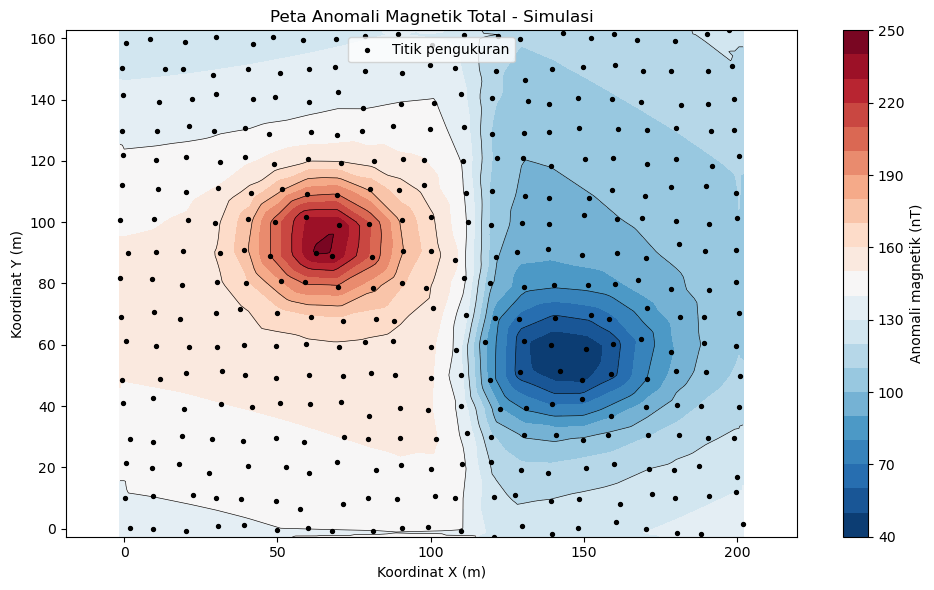

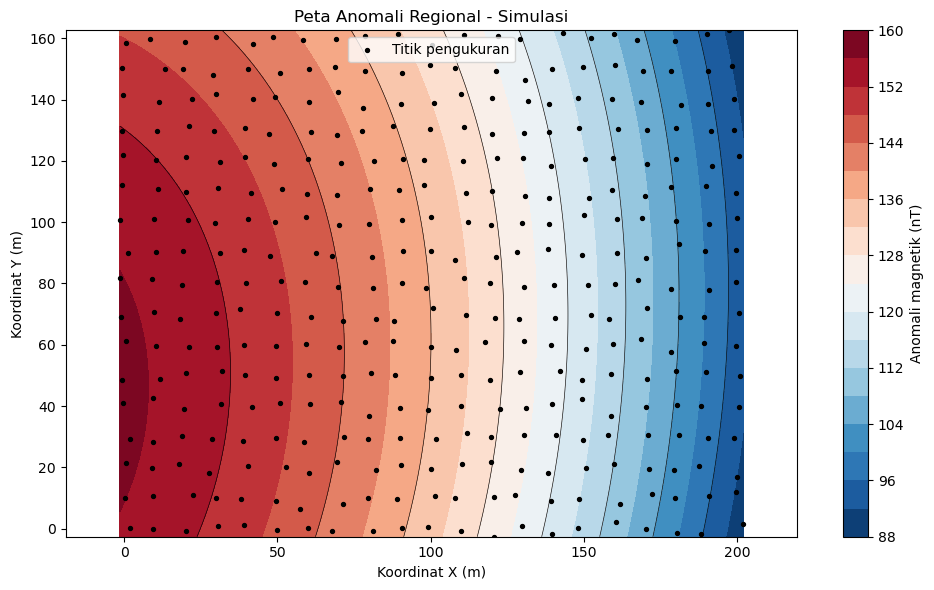

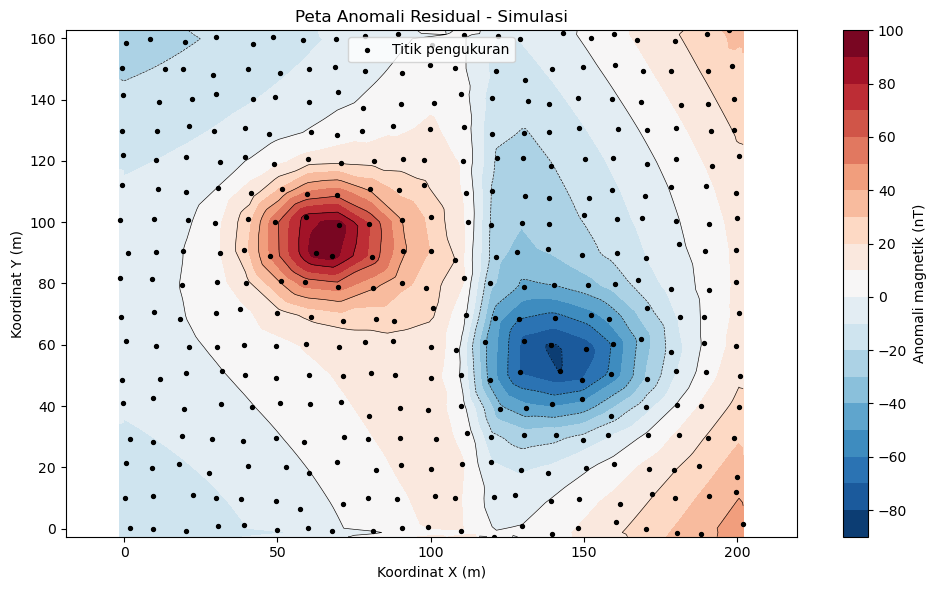


Statistik anomali magnetik total:
count    357.000000
mean     130.369172
std       31.004612
min       40.505400
25%      109.095030
50%      133.732279
75%      150.039477
max      242.303199
Name: anomali_magnetik_nT, dtype: float64

Statistik anomali residual:
count    3.570000e+02
mean    -2.098589e-13
std      2.446221e+01
min     -8.152037e+01
25%     -1.188015e+01
50%     -2.082455e-01
75%      1.167298e+01
max      9.681280e+01
Name: anomali_residual_nT, dtype: float64

File berhasil disimpan:
- hasil_koreksi_magnetik.csv
- hasil_pengolahan_magnetik.csv


In [5]:

# ============================================================
# PENGOLAHAN DATA GEOMAGNETIK - DATA SIMULASI
# Koreksi variasi harian, IGRF, regional-residual, peta kontur
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from scipy.linalg import lstsq

# ------------------------------------------------------------
# 1. MEMBUAT DATA SIMULASI
# ------------------------------------------------------------
# Bagian ini digunakan karena data lapangan belum tersedia.
# Ganti bagian simulasi dengan pd.read_csv("data_magnetik.csv")
# jika sudah memiliki data pengukuran asli.

np.random.seed(7)

xv = np.linspace(0, 200, 21)
yv = np.linspace(0, 160, 17)
X, Y = np.meshgrid(xv, yv)

x = X.ravel() + np.random.normal(0, 1.2, X.size)
y = Y.ravel() + np.random.normal(0, 1.2, Y.size)

# Medan regional simulasi (nT)
regional_asli = 120 + 0.12*x - 0.08*y + 0.0004*(x-100)**2

# Anomali lokal simulasi
anomali_1 = 95 * np.exp(
    -(((x-65)/22)**2 + ((y-95)/18)**2)
)

anomali_2 = -65 * np.exp(
    -(((x-145)/30)**2 + ((y-55)/20)**2)
)

anomali_struktur = (
    -35 * np.tanh((x-115)/7)
    * np.exp(-((y-80)/80)**2)
)

residual_asli = anomali_1 + anomali_2 + anomali_struktur

# Nilai IGRF simulasi dan variasi harian simulasi
igrf = 43000 + 0.015*x - 0.01*y

variasi_harian = (
    8 * np.sin(np.linspace(0, 4*np.pi, len(x)))
    + np.random.normal(0, 0.8, len(x))
)

anomali_total_asli = regional_asli + residual_asli

# Medan magnet total hasil pengukuran simulasi
T_obs = igrf + variasi_harian + anomali_total_asli

data = pd.DataFrame({
    "X_m": x,
    "Y_m": y,
    "T_obs_nT": T_obs,
    "variasi_harian_nT": variasi_harian,
    "IGRF_nT": igrf
})

print("Contoh data simulasi:")
print(data.head())

# ------------------------------------------------------------
# 2. KOREKSI VARIASI HARIAN
# ------------------------------------------------------------
# Diasumsikan kolom variasi_harian_nT adalah perubahan medan
# terhadap nilai referensi base station pada waktu pengukuran.
#
# Untuk data lapangan, variasi harus dihitung dari pengukuran
# base station yang waktunya sesuai/interpolasi ke waktu survei.

data["T_setelah_koreksi_harian_nT"] = (
    data["T_obs_nT"] - data["variasi_harian_nT"]
)

# ------------------------------------------------------------
# 3. KOREKSI IGRF
# ------------------------------------------------------------
# IGRF pada contoh ini adalah nilai simulasi, bukan nilai IGRF
# resmi. Untuk data lapangan, gunakan nilai IGRF sesuai lokasi,
# tanggal, dan ketinggian pengukuran.

data["anomali_magnetik_nT"] = (
    data["T_setelah_koreksi_harian_nT"] - data["IGRF_nT"]
)

print("\nTabel hasil koreksi:")
print(data[[
    "X_m", "Y_m", "T_obs_nT",
    "T_setelah_koreksi_harian_nT",
    "IGRF_nT", "anomali_magnetik_nT"
]].head())

data.to_csv("hasil_koreksi_magnetik.csv", index=False)

# ------------------------------------------------------------
# 4. MEMBUAT GRID UNTUK PETA KONTUR
# ------------------------------------------------------------

xi = np.linspace(data["X_m"].min(), data["X_m"].max(), 150)
yi = np.linspace(data["Y_m"].min(), data["Y_m"].max(), 120)
XI, YI = np.meshgrid(xi, yi)

Z = griddata(
    (data["X_m"], data["Y_m"]),
    data["anomali_magnetik_nT"],
    (XI, YI),
    method="linear"
)

# Isi area kosong pada batas grid dengan interpolasi nearest
Z_nearest = griddata(
    (data["X_m"], data["Y_m"]),
    data["anomali_magnetik_nT"],
    (XI, YI),
    method="nearest"
)

Z = np.where(np.isnan(Z), Z_nearest, Z)

# ------------------------------------------------------------
# 5. PEMISAHAN ANOMALI REGIONAL DAN RESIDUAL
# ------------------------------------------------------------
# Regional dihitung dengan fitting polinomial orde dua.
# Metode ini sesuai untuk demonstrasi tren regional yang halus.
# Orde polinomial harus dievaluasi kembali pada data lapangan.

def buat_matriks_polinomial(x, y):
    return np.column_stack([
        np.ones_like(x),
        x, y,
        x**2, x*y, y**2
    ])

A = buat_matriks_polinomial(
    data["X_m"].to_numpy(),
    data["Y_m"].to_numpy()
)

b = data["anomali_magnetik_nT"].to_numpy()

koefisien, *_ = lstsq(A, b)

data["anomali_regional_nT"] = A @ koefisien

data["anomali_residual_nT"] = (
    data["anomali_magnetik_nT"]
    - data["anomali_regional_nT"]
)

# Evaluasi regional pada grid peta
AG = buat_matriks_polinomial(
    XI.ravel(), YI.ravel()
)

Z_regional = (AG @ koefisien).reshape(XI.shape)
Z_residual = Z - Z_regional

# ------------------------------------------------------------
# 6. FUNGSI UNTUK MEMBUAT PETA KONTUR
# ------------------------------------------------------------

def peta_kontur(XI, YI, Z, judul, satuan="nT"):
    plt.figure(figsize=(10, 6))

    kontur = plt.contourf(
        XI, YI, Z,
        levels=20,
        cmap="RdBu_r"
    )

    plt.contour(
        XI, YI, Z,
        levels=10,
        colors="black",
        linewidths=0.45
    )

    plt.colorbar(kontur, label=f"Anomali magnetik ({satuan})")
    plt.scatter(
        data["X_m"], data["Y_m"],
        s=8, c="black", label="Titik pengukuran"
    )

    plt.xlabel("Koordinat X (m)")
    plt.ylabel("Koordinat Y (m)")
    plt.title(judul)
    plt.axis("equal")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Peta 1: anomali magnetik total
peta_kontur(
    XI, YI, Z,
    "Peta Anomali Magnetik Total - Simulasi"
)

# Peta 2: anomali regional
peta_kontur(
    XI, YI, Z_regional,
    "Peta Anomali Regional - Simulasi"
)

# Peta 3: anomali residual
peta_kontur(
    XI, YI, Z_residual,
    "Peta Anomali Residual - Simulasi"
)

# ------------------------------------------------------------
# 7. RINGKASAN HASIL DAN SIMPAN DATA
# ------------------------------------------------------------

print("\nStatistik anomali magnetik total:")
print(data["anomali_magnetik_nT"].describe())

print("\nStatistik anomali residual:")
print(data["anomali_residual_nT"].describe())

data.to_csv("hasil_pengolahan_magnetik.csv", index=False)

print("\nFile berhasil disimpan:")
print("- hasil_koreksi_magnetik.csv")
print("- hasil_pengolahan_magnetik.csv")


### Interpretasi Penampang Anomali Magnetik 2D

1. **Anomali Magnetik Positif:**  
   Nilai anomali magnetik relatif tinggi \(\rightarrow\) dapat mengindikasikan keberadaan batuan dengan suseptibilitas magnetik tinggi, seperti batuan beku mafik atau tubuh intrusi tertentu.

2. **Anomali Magnetik Negatif:**  
   Nilai anomali magnetik relatif rendah \(\rightarrow\) dapat berkaitan dengan batuan yang memiliki suseptibilitas magnetik lebih rendah, zona alterasi, atau pengaruh arah magnetisasi batuan.

3. **Zona Gradien Magnetik Tinggi:**  
   Perubahan nilai anomali magnetik secara tajam \(\rightarrow\) dapat menunjukkan batas kontak litologi, perubahan sifat magnetik batuan, atau kemungkinan keberadaan struktur sesar.

4. **Anomali Berbentuk Memanjang:**  
   Pola anomali magnetik yang memanjang \(\rightarrow\) dapat mengindikasikan struktur geologi dengan arah dominan tertentu, seperti kontak batuan atau zona struktur, tetapi perlu dikonfirmasi dengan data pendukung.

5. **Pemisahan Anomali Regional dan Residual:**  
   Anomali regional menggambarkan variasi medan magnet berskala luas, sedangkan anomali residual menonjolkan variasi lokal yang berpotensi berkaitan dengan sumber anomali yang lebih dangkal atau berskala kecil.

**Kesimpulan:**

Peta anomali magnetik menunjukkan variasi sifat kemagnetan batuan bawah permukaan yang dapat digunakan untuk mengidentifikasi kemungkinan perbedaan litologi, tubuh intrusi, dan struktur geologi seperti sesar. Pemisahan anomali regional dan residual membantu memperjelas variasi magnetik lokal terhadap kecenderungan anomali berskala luas. Namun, interpretasi tersebut masih bersifat awal karena menggunakan data simulasi dan tidak dapat memastikan jenis batuan maupun keberadaan struktur geologi secara langsung. Oleh karena itu, hasil analisis perlu divalidasi menggunakan data geologi regional, informasi suseptibilitas batuan, atau metode geofisika pendukung.

---------------------------------------------------------------

### ***PROMPT 4 : PENGOLAHAN DATA METODE GRAVITASI***

#### ***Struktur Prompt***

Judul: Analisis Data Gravitasi untuk Identifikasi Struktur Geologi dan Kontras Densitas Bawah Permukaan

Bertindaklah sebagai ahli geofisika terapan dan dosen pembimbing yang memiliki keahlian dalam metode gravitasi. Lakukan pengolahan dan analisis data gravitasi untuk mengidentifikasi variasi medan gravitasi bumi, menghitung anomali Bouguer, memisahkan anomali regional dan residual, serta menginterpretasikan distribusi densitas dan struktur geologi bawah permukaan. Gunakan koreksi gravitasi yang sesuai, seperti koreksi lintang, udara bebas, Bouguer, dan medan. Sajikan tahapan pengolahan data secara sistematis, perhitungan matematis, kode Python, peta kontur, serta interpretasi geologi berdasarkan hasil analisis.


TABEL HASIL KOREKSI GRAVITASI
     X_m  Y_m  Lintang_deg  Bujur_deg  Elevasi_m  Gravitasi_observasi_mGal  \
0    0.0  0.0         -5.0    119.000    20.0000               978067.6549   
1  200.0  0.0         -5.0    119.002    29.8942               978065.7741   
2  400.0  0.0         -5.0    119.004    39.1736               978063.9929   
3  600.0  0.0         -5.0    119.006    47.3204               978062.4342   
4  800.0  0.0         -5.0    119.008    53.9957               978061.1810   

   Gravitasi_normal_mGal  FAC_mGal  Bouguer_mGal  Terrain_correction_mGal  \
0            978071.8978    6.1720        2.2391                   0.1500   
1            978071.8978    9.2253        3.3467                   0.1652   
2            978071.8978   12.0890        4.3856                   0.2015   
3            978071.8978   14.6031        5.2977                   0.2369   
4            978071.8978   16.6631        6.0450                   0.2499   

   Anomali_awal_mGal  Setelah_FAC_mGal

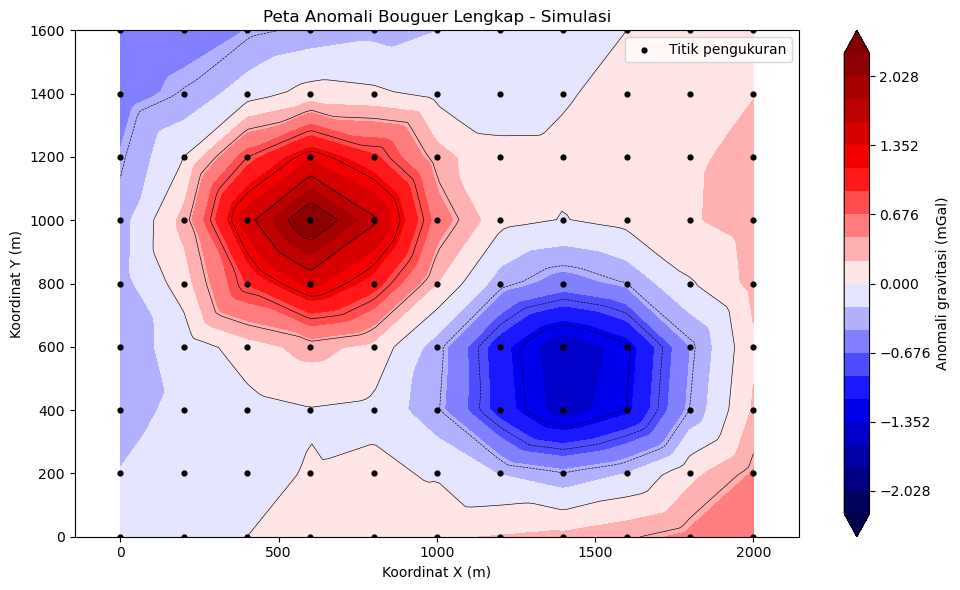

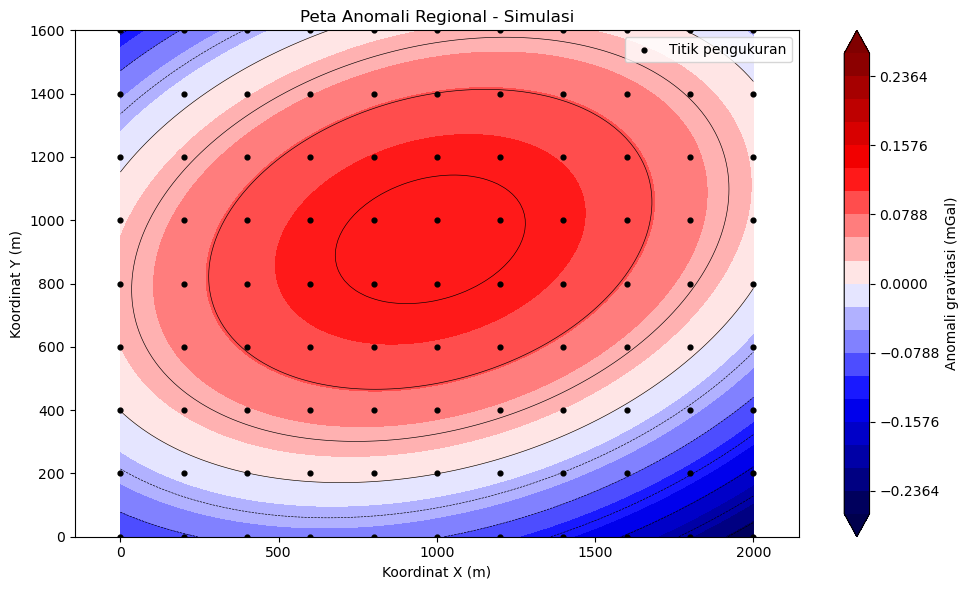

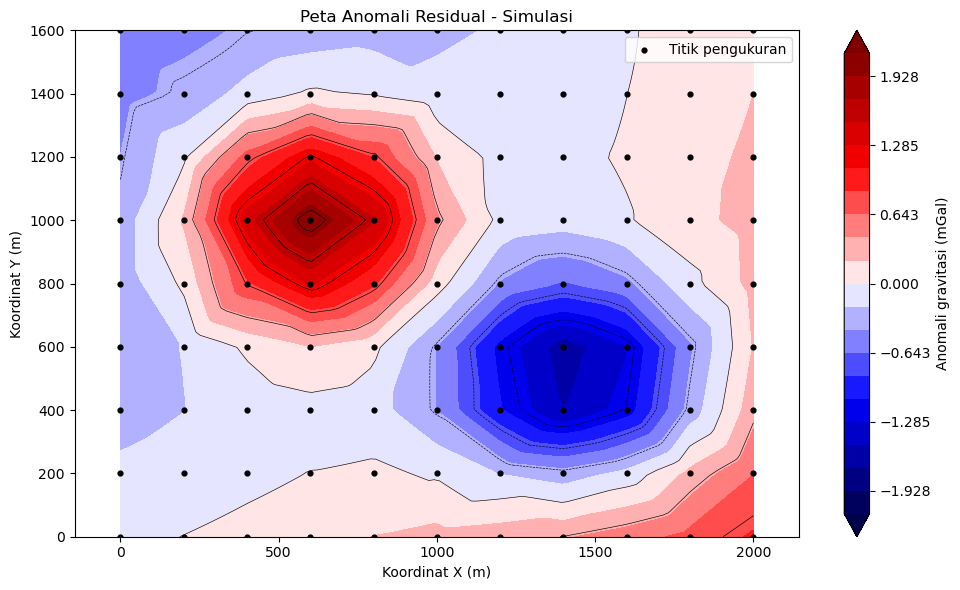


STATISTIK ANOMALI BOUGUER LENGKAP (mGal)
count    99.0000
mean      0.0195
std       0.5844
min      -1.5397
25%      -0.2823
50%      -0.0001
75%       0.2124
max       2.2786
Name: Anomali_Bouguer_lengkap_mGal, dtype: float64

STATISTIK ANOMALI RESIDUAL (mGal)
count    99.0000
mean     -0.0000
std       0.5789
min      -1.6118
25%      -0.2899
50%      -0.0385
75%       0.2162
max       2.1676
Name: Residual_mGal, dtype: float64

File berhasil disimpan:
1. hasil_koreksi_gravitasi.csv
2. hasil_pengolahan_gravitasi.csv


In [7]:

# ============================================================
# PENGOLAHAN DATA GRAVITASI - SIMULASI
# Koreksi lintang, udara bebas, Bouguer, medan
# Anomali Bouguer lengkap, regional, residual, dan peta kontur
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from matplotlib.colors import TwoSlopeNorm

np.random.seed(10)

# ------------------------------------------------------------
# 1. DATA SIMULASI
# ------------------------------------------------------------

xv = np.linspace(0, 2000, 11)
yv = np.linspace(0, 1600, 9)
X, Y = np.meshgrid(xv, yv)

x = X.ravel()
y = Y.ravel()

latitude = -5.0 + (y / 1600) * 0.02
longitude = 119.0 + (x / 2000) * 0.02
elevation = 20 + 0.03*x + 0.015*y + 10*np.sin(x/500)

# Densitas Bouguer (g/cm^3)
rho = 2.67

# Anomali gravitasi bawah permukaan simulasi (mGal)
regional_asli = 0.0004*(x-1000) - 0.0003*(y-800)

anomali_positif = 2.5*np.exp(
    -(((x-600)/350)**2 + ((y-1000)/300)**2)
)

anomali_negatif = -2.0*np.exp(
    -(((x-1450)/400)**2 + ((y-500)/300)**2)
)

anomali_asli = regional_asli + anomali_positif + anomali_negatif

# Gravitasi normal: persamaan Somigliana
phi = np.deg2rad(latitude)
gamma_e = 978032.67715
k = 0.001931851353
e2 = 0.00669437999013

g_normal = gamma_e * (
    (1 + k*np.sin(phi)**2)
    / np.sqrt(1 - e2*np.sin(phi)**2)
)

# Koreksi udara bebas dan Bouguer
FAC = 0.3086 * elevation
BC = 0.04193 * rho * elevation

# Terrain correction simulasi
# Data lapangan memerlukan perhitungan dari topografi/DEM.
TC = 0.15 + 0.10*np.sin(x/500)**2

# Membuat gravitasi observasi simulasi
g_obs = g_normal + anomali_asli - FAC + BC - TC

data = pd.DataFrame({
    "X_m": x,
    "Y_m": y,
    "Lintang_deg": latitude,
    "Bujur_deg": longitude,
    "Elevasi_m": elevation,
    "Gravitasi_observasi_mGal": g_obs,
    "Gravitasi_normal_mGal": g_normal,
    "FAC_mGal": FAC,
    "Bouguer_mGal": BC,
    "Terrain_correction_mGal": TC
})

# ------------------------------------------------------------
# 2. KOREKSI LINTANG
# ------------------------------------------------------------

data["Anomali_awal_mGal"] = (
    data["Gravitasi_observasi_mGal"]
    - data["Gravitasi_normal_mGal"]
)

# ------------------------------------------------------------
# 3. KOREKSI UDARA BEBAS
# ------------------------------------------------------------

data["Setelah_FAC_mGal"] = (
    data["Anomali_awal_mGal"]
    + data["FAC_mGal"]
)

# ------------------------------------------------------------
# 4. KOREKSI BOUGUER
# ------------------------------------------------------------

data["Anomali_Bouguer_sederhana_mGal"] = (
    data["Setelah_FAC_mGal"]
    - data["Bouguer_mGal"]
)

# ------------------------------------------------------------
# 5. KOREKSI MEDAN DAN ANOMALI BOUGUER LENGKAP
# ------------------------------------------------------------

data["Anomali_Bouguer_lengkap_mGal"] = (
    data["Anomali_Bouguer_sederhana_mGal"]
    + data["Terrain_correction_mGal"]
)

print("TABEL HASIL KOREKSI GRAVITASI")
print(data.head().round(4))

data.to_csv("hasil_koreksi_gravitasi.csv", index=False)

# ------------------------------------------------------------
# 6. INTERPOLASI DATA KE GRID
# ------------------------------------------------------------

xi = np.linspace(data["X_m"].min(), data["X_m"].max(), 120)
yi = np.linspace(data["Y_m"].min(), data["Y_m"].max(), 100)
XI, YI = np.meshgrid(xi, yi)

nilai = data["Anomali_Bouguer_lengkap_mGal"].to_numpy()

Z = griddata(
    (data["X_m"], data["Y_m"]),
    nilai,
    (XI, YI),
    method="linear"
)

Z_nearest = griddata(
    (data["X_m"], data["Y_m"]),
    nilai,
    (XI, YI),
    method="nearest"
)

Z = np.where(np.isnan(Z), Z_nearest, Z)

# ------------------------------------------------------------
# 7. PEMISAHAN REGIONAL DAN RESIDUAL
# ------------------------------------------------------------

def matriks_polinomial(x, y):
    return np.column_stack([
        np.ones_like(x),
        x,
        y,
        x**2,
        x*y,
        y**2
    ])

A = matriks_polinomial(
    data["X_m"].to_numpy(),
    data["Y_m"].to_numpy()
)

koef, *_ = np.linalg.lstsq(A, nilai, rcond=None)

data["Regional_mGal"] = A @ koef

data["Residual_mGal"] = (
    data["Anomali_Bouguer_lengkap_mGal"]
    - data["Regional_mGal"]
)

AG = matriks_polinomial(XI.ravel(), YI.ravel())

Z_regional = (AG @ koef).reshape(XI.shape)
Z_residual = Z - Z_regional

data.to_csv("hasil_pengolahan_gravitasi.csv", index=False)

# ------------------------------------------------------------
# 8. FUNGSI PETA KONTUR
# ------------------------------------------------------------

def plot_kontur(XI, YI, Z, judul):
    # Rentang warna simetris terhadap nol
    batas = np.nanmax(np.abs(Z))

    if batas == 0 or not np.isfinite(batas):
        batas = 1.0

    norm = TwoSlopeNorm(
        vmin=-batas,
        vcenter=0,
        vmax=batas
    )

    plt.figure(figsize=(10, 6))

    cf = plt.contourf(
        XI,
        YI,
        Z,
        levels=np.linspace(-batas, batas, 21),
        cmap="seismic",
        norm=norm,
        extend="both"
    )

    plt.contour(
        XI,
        YI,
        Z,
        levels=10,
        colors="black",
        linewidths=0.45
    )

    plt.scatter(
        data["X_m"],
        data["Y_m"],
        s=12,
        c="black",
        label="Titik pengukuran"
    )

    plt.colorbar(
        cf,
        label="Anomali gravitasi (mGal)"
    )

    plt.xlabel("Koordinat X (m)")
    plt.ylabel("Koordinat Y (m)")
    plt.title(judul)
    plt.axis("equal")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 9. MEMBUAT TIGA PETA KONTUR
# ------------------------------------------------------------

plot_kontur(
    XI,
    YI,
    Z,
    "Peta Anomali Bouguer Lengkap - Simulasi"
)

plot_kontur(
    XI,
    YI,
    Z_regional,
    "Peta Anomali Regional - Simulasi"
)

plot_kontur(
    XI,
    YI,
    Z_residual,
    "Peta Anomali Residual - Simulasi"
)

# ------------------------------------------------------------
# 10. STATISTIK HASIL
# ------------------------------------------------------------

print("\nSTATISTIK ANOMALI BOUGUER LENGKAP (mGal)")
print(data["Anomali_Bouguer_lengkap_mGal"].describe().round(4))

print("\nSTATISTIK ANOMALI RESIDUAL (mGal)")
print(data["Residual_mGal"].describe().round(4))

print("\nFile berhasil disimpan:")
print("1. hasil_koreksi_gravitasi.csv")
print("2. hasil_pengolahan_gravitasi.csv")



### Interpretasi Penampang Anomali Gravitasi 2D

1. **Anomali Gravitasi Positif:**  
   Nilai anomali gravitasi relatif tinggi \(\rightarrow\) dapat menunjukkan keberadaan material dengan densitas relatif lebih tinggi daripada batuan di sekitarnya, seperti batuan beku mafik atau tubuh batuan kompak.

2. **Anomali Gravitasi Negatif:**  
   Nilai anomali gravitasi relatif rendah \(\rightarrow\) dapat berkaitan dengan material berdensitas rendah, seperti sedimen lepas, cekungan sedimen, atau zona batuan yang mengalami pelapukan intensif.

3. **Zona Gradien Gravitasi Tinggi:**  
   Perubahan nilai anomali gravitasi secara tajam \(\rightarrow\) dapat menunjukkan batas kontras densitas, kontak litologi, atau kemungkinan struktur geologi seperti sesar.

4. **Anomali Gravitasi Berbentuk Memanjang:**  
   Pola anomali yang memanjang \(\rightarrow\) dapat mengindikasikan perubahan densitas yang mengikuti arah struktur tertentu, seperti batas cekungan, kontak batuan, atau tubuh geologi memanjang.

5. **Pemisahan Anomali Regional dan Residual:**  
   Anomali regional menggambarkan kecenderungan gravitasi berskala luas, sedangkan anomali residual menonjolkan variasi lokal yang berpotensi berkaitan dengan kontras densitas pada skala yang lebih kecil.

**Kesimpulan:**

Pengolahan data gravitasi dilakukan melalui koreksi lintang, udara bebas, Bouguer, dan medan untuk memperoleh anomali Bouguer lengkap. Pemisahan anomali regional dan residual membantu mengidentifikasi variasi gravitasi yang berpotensi berhubungan dengan perbedaan densitas batuan bawah permukaan. Anomali positif dapat mengindikasikan material yang relatif lebih rapat, sedangkan anomali negatif dapat berkaitan dengan material yang relatif kurang rapat dibandingkan lingkungan sekitarnya.

Namun, interpretasi tersebut masih bersifat awal karena menggunakan data simulasi. Anomali gravitasi tidak dapat menentukan jenis batuan atau keberadaan sesar secara unik tanpa informasi pendukung. Oleh karena itu, hasil pengolahan perlu divalidasi menggunakan data geologi regional, informasi densitas batuan, dan metode geofisika lainnya.


------------------------------------------------------------------------
### ***KASUS/PROMPT 5 : PENGOLAHAN DATA MAGNETOTELURIK (MT)***

#### ***Struktur Prompt***

Judul: Analisis Data Magnetotelurik untuk Identifikasi Struktur Resistivitas Bawah Permukaan dan Eksplorasi Panas Bumi

Bertindaklah sebagai ahli geofisika terapan dan dosen pembimbing yang memiliki keahlian dalam metode magnetotelurik (MT). Lakukan pengolahan dan analisis data magnetotelurik untuk mengidentifikasi distribusi resistivitas bawah permukaan berdasarkan variasi medan listrik dan medan magnet alami bumi. Gunakan analisis impedansi, kurva resistivitas semu, fase, serta pemodelan inversi 1D atau 2D untuk memperkirakan struktur resistivitas bawah permukaan. Sajikan tahapan pengolahan data secara sistematis, persamaan matematis, kode Python jika memungkinkan, grafik, serta interpretasi geologi yang berkaitan dengan sistem panas bumi.


CONTOH HASIL PENGOLAHAN MT
Stasiun  Jarak_m  Frekuensi_Hz  Periode_s  Ex_real_V_per_m  Ex_imag_V_per_m  Hy_real_A_per_m  Hy_imag_A_per_m  Zxy_real_ohm  Zxy_imag_ohm  Resistivitas_semu_ohm_m  Fase_derajat  Skin_depth_m
    MT1        0        0.0100   100.0000              0.0              0.0            0.001              0.0        0.0025        0.0021                 134.6686       38.9934    58371.5448
    MT1        0        0.0145    68.9779              0.0              0.0            0.001              0.0        0.0031        0.0024                 133.7390       37.9836    48311.6492
    MT1        0        0.0210    47.5794              0.0              0.0            0.001              0.0        0.0037        0.0028                 127.7929       36.6914    39222.1115
    MT1        0        0.0305    32.8193              0.0              0.0            0.001              0.0        0.0043        0.0031                 118.2180       35.7407    31331.0077
    MT1        0  

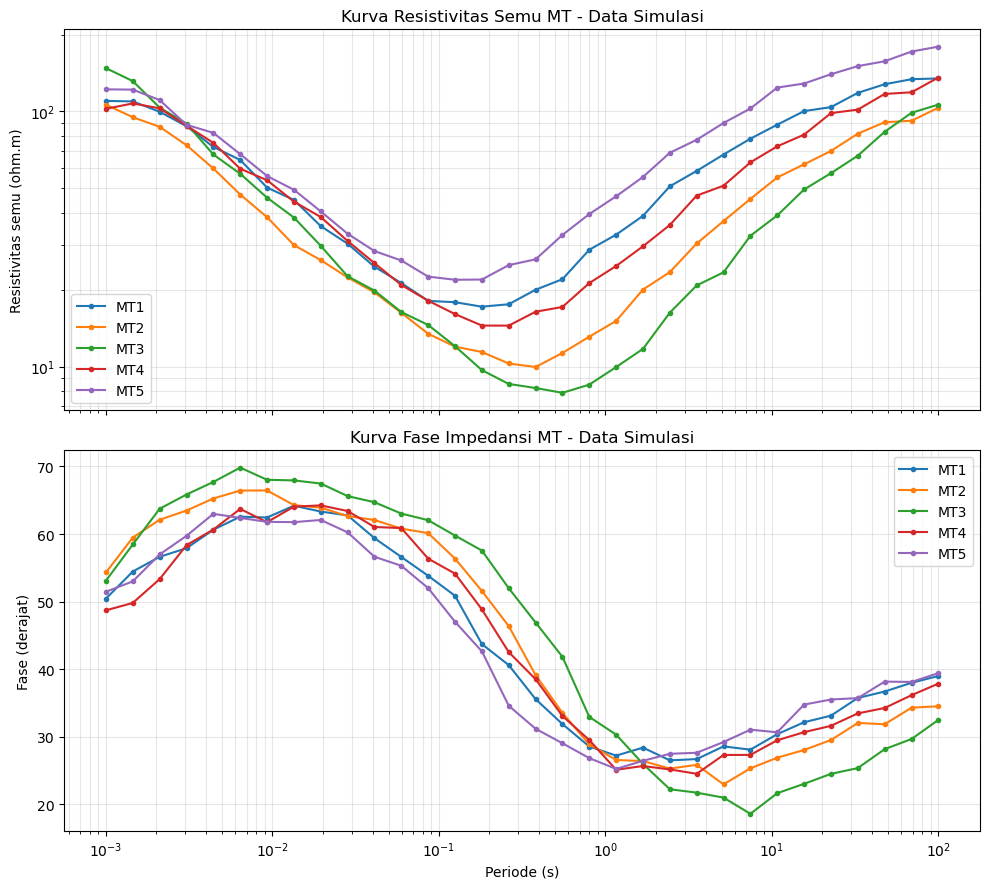

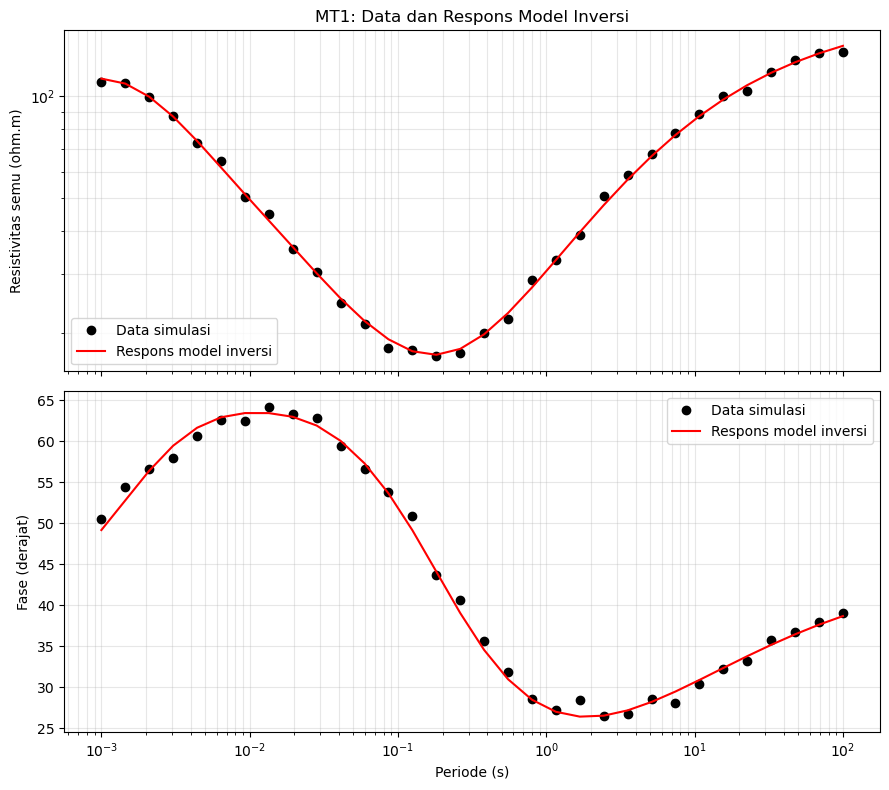

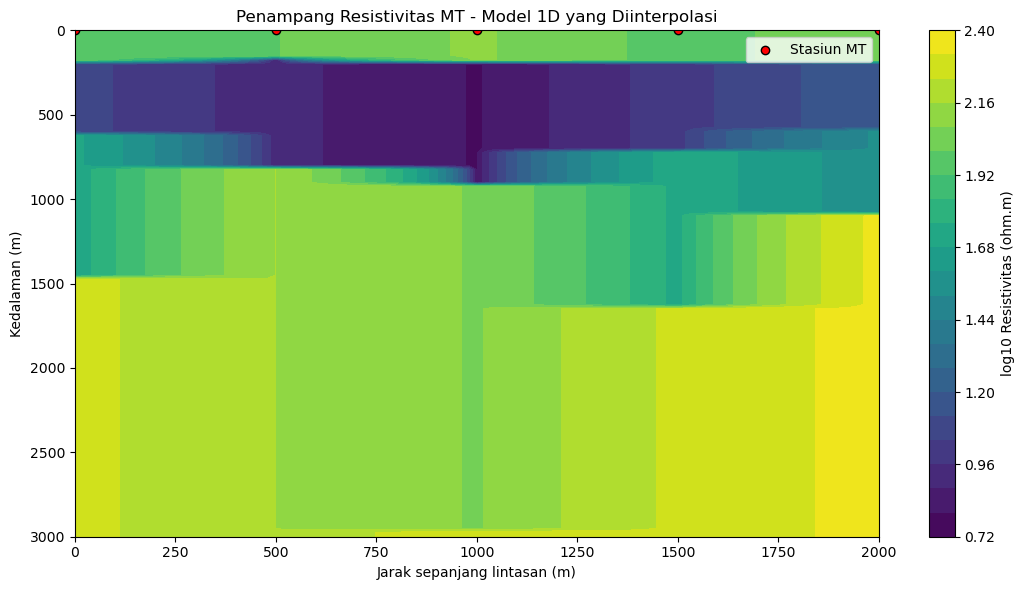

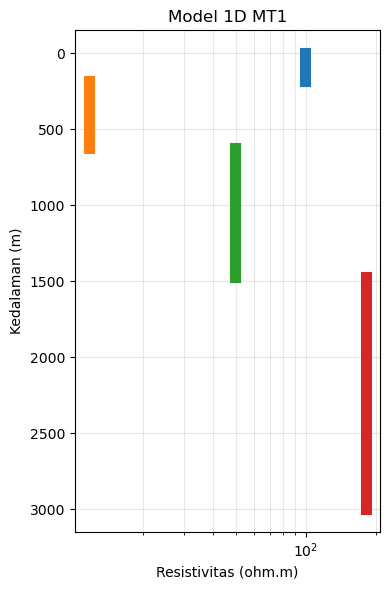

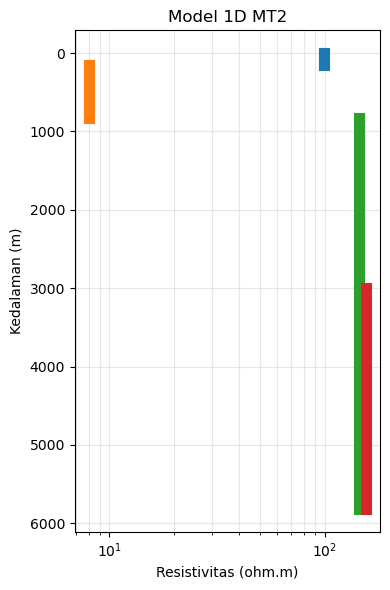

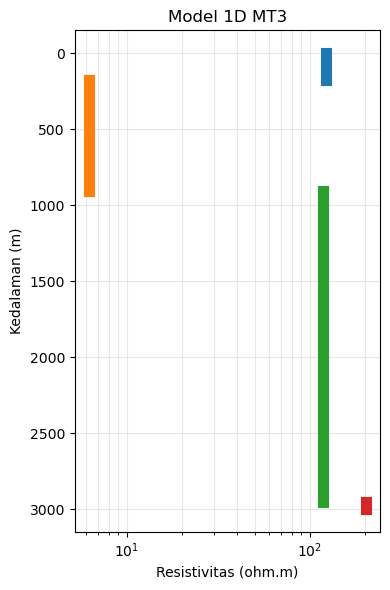

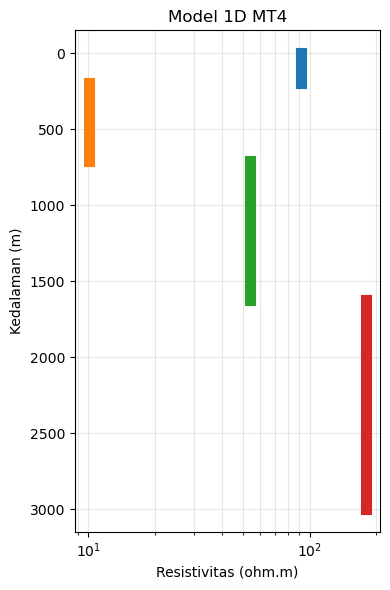

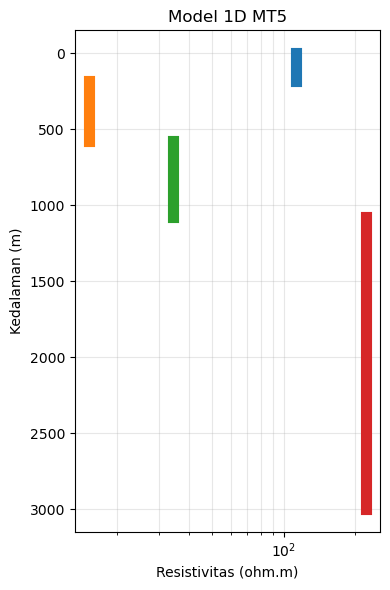


RINGKASAN RESISTIVITAS HASIL INVERSI (ohm.m)
Stasiun  rho1_ohm_m  rho2_ohm_m  rho3_ohm_m  rho4_ohm_m  RMS_normalisasi  RMS_log10_rhoa
    MT1      98.910      11.651      49.670     182.131            0.339           0.012
    MT2      99.398       8.004     144.555     155.990            0.337           0.014
    MT3     123.345       6.212     118.281     203.236            0.361           0.016
    MT4      91.911      10.021      53.599     180.362            0.325           0.013
    MT5     112.789      15.153      34.347     222.125            0.311           0.011

File berhasil disimpan:
- hasil_pengolahan_MT_simulasi.csv
- hasil_inversi_1D_MT_simulasi.csv

Catatan: semua data merupakan SIMULASI.
Model 1D dan penampang interpolasi tidak menggantikan inversi 2D.


In [8]:

# ==============================================================
# PENGOLAHAN DATA MAGNETOTELURIK (MT) - DATA SIMULASI
# Analisis impedansi, resistivitas semu, fase, inversi 1D,
# dan penampang resistivitas untuk studi pendahuluan panas bumi.
#
# CATATAN:
# 1. Data ini SIMULASI, bukan pengukuran lapangan.
# 2. Inversi menggunakan model bumi berlapis 1D.
# 3. Penampang antartitik merupakan interpolasi model 1D,
#    BUKAN hasil inversi MT 2D penuh.
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.interpolate import griddata

np.random.seed(10)

# --------------------------------------------------------------
# 1. PARAMETER DASAR DAN FREKUENSI
# --------------------------------------------------------------

MU0 = 4 * np.pi * 1e-7  # Permeabilitas magnetik vakum (H/m)

frekuensi = np.logspace(-2, 3, 32)  # 0.01-1000 Hz
periode = 1 / frekuensi

# Lima stasiun dengan model resistivitas simulasi yang berbeda.
# Resistivitas (ohm.m) dan ketebalan lapisan (m).
model_simulasi = [
    {"rho": [100, 12, 70, 180], "h": [180, 500, 1000]},
    {"rho": [100, 8, 60, 160],   "h": [150, 600, 1200]},
    {"rho": [120, 6, 50, 200],   "h": [180, 650, 1100]},
    {"rho": [90, 10, 80, 180],   "h": [200, 550, 1000]},
    {"rho": [110, 15, 90, 220],  "h": [180, 500, 900]}
]

jarak_stasiun = np.array([0, 500, 1000, 1500, 2000])
nama_stasiun = [f"MT{i+1}" for i in range(len(jarak_stasiun))]


# --------------------------------------------------------------
# 2. FUNGSI RESPONS IMPEDANSI BUMI BERLAPIS 1D
# --------------------------------------------------------------

def impedansi_1d(freq, rho, ketebalan):
    """
    Menghitung impedansi permukaan untuk bumi berlapis 1D.
    freq       : frekuensi (Hz)
    rho        : resistivitas tiap lapisan (ohm.m)
    ketebalan  : ketebalan tiap lapisan selain half-space (m)

    Hasil:
    impedansi kompleks dalam ohm, dengan E (V/m) dan H (A/m).
    """
    hasil = []

    for f in np.asarray(freq):
        omega = 2 * np.pi * f

        # Impedansi half-space pada lapisan terbawah
        Z = np.sqrt(1j * omega * MU0 * rho[-1])

        # Rekursi dari lapisan terbawah menuju permukaan
        for j in range(len(rho) - 2, -1, -1):
            gamma = np.sqrt(1j * omega * MU0 / rho[j])
            Z0 = np.sqrt(1j * omega * MU0 * rho[j])
            tanh_term = np.tanh(gamma * ketebalan[j])

            Z = Z0 * (
                (Z + Z0 * tanh_term) /
                (Z0 + Z * tanh_term)
            )

        hasil.append(Z)

    return np.asarray(hasil)


# --------------------------------------------------------------
# 3. SIMULASI MEDAN LISTRIK DAN MEDAN MAGNET
# --------------------------------------------------------------

semua_data = []
data_inversi = []

for i, model in enumerate(model_simulasi):
    rho_true = np.asarray(model["rho"], dtype=float)
    h_true = np.asarray(model["h"], dtype=float)

    # Respons impedansi teoritis dari model simulasi
    Z_teori = impedansi_1d(frekuensi, rho_true, h_true)

    # Noise kompleks kecil untuk meniru ketidakpastian data
    rng = np.random.default_rng(100 + i)
    noise = (
        rng.normal(0, 0.015, len(frekuensi))
        + 1j * rng.normal(0, 0.015, len(frekuensi))
    )
    Z_ukur = Z_teori * (1 + noise)

    # Simulasi komponen medan frekuensi-domain.
    # Hy dan Hx dalam A/m; Ex dan Ey dalam V/m.
    # Ini adalah estimasi kompleks sintetis, bukan time series mentah.
    Hy = np.full(len(frekuensi), 1e-3 + 0j)
    Hx = np.full(len(frekuensi), 1e-3 + 0j)
    Ex = Z_ukur * Hy
    Ey = -Z_ukur * Hx

    # Impedansi silang. Dalam kasus 1D ideal, komponen silang
    # mempunyai besar yang sama; tanda bergantung konvensi sumbu.
    Zxy = Ex / Hy
    Zyx = -Ey / Hx

    # Resistivitas semu dan fase dari Zxy
    rhoa = np.abs(Zxy)**2 / (MU0 * 2 * np.pi * frekuensi)
    fase = np.degrees(np.arctan2(Zxy.imag, Zxy.real))

    # Skin depth sebagai perkiraan awal penetrasi
    skin_depth = 503 * np.sqrt(rhoa / frekuensi)

    for j in range(len(frekuensi)):
        semua_data.append({
            "Stasiun": nama_stasiun[i],
            "Jarak_m": jarak_stasiun[i],
            "Frekuensi_Hz": frekuensi[j],
            "Periode_s": periode[j],
            "Ex_real_V_per_m": Ex[j].real,
            "Ex_imag_V_per_m": Ex[j].imag,
            "Hy_real_A_per_m": Hy[j].real,
            "Hy_imag_A_per_m": Hy[j].imag,
            "Zxy_real_ohm": Zxy[j].real,
            "Zxy_imag_ohm": Zxy[j].imag,
            "Resistivitas_semu_ohm_m": rhoa[j],
            "Fase_derajat": fase[j],
            "Skin_depth_m": skin_depth[j]
        })

    # ----------------------------------------------------------
    # 4. INVERSI 1D
    # ----------------------------------------------------------
    # Model empat lapisan: tiga lapisan berketebalan tertentu
    # dan lapisan terakhir berupa half-space.
    # Parameter dioptimasi dalam skala log10.

    rhoa_observasi = rhoa.copy()
    fase_observasi = fase.copy()

    def unpack_parameter(p):
        rho = 10**p[:4]
        h = 10**p[4:]
        return rho, h

    def fungsi_residual(p):
        rho, h = unpack_parameter(p)
        Z_model = impedansi_1d(frekuensi, rho, h)

        rhoa_model = (
            np.abs(Z_model)**2 /
            (MU0 * 2 * np.pi * frekuensi)
        )
        fase_model = np.degrees(
            np.arctan2(Z_model.imag, Z_model.real)
        )

        # Residual log resistivitas dan residual fase
        residual_rhoa = (
            np.log10(rhoa_model) - np.log10(rhoa_observasi)
        ) / 0.04
        residual_fase = (fase_model - fase_observasi) / 2.5

        return np.r_[residual_rhoa, residual_fase]

    # Tebakan awal model
    p0 = np.r_[
        np.log10([100, 10, 70, 180]),
        np.log10([180, 550, 1000])
    ]

    batas_bawah = np.r_[
        np.log10([1, 1, 1, 1]),
        np.log10([20, 50, 100])
    ]
    batas_atas = np.r_[
        np.log10([1000, 1000, 1000, 1000]),
        np.log10([1000, 3000, 5000])
    ]

    hasil_inv = least_squares(
        fungsi_residual,
        p0,
        bounds=(batas_bawah, batas_atas),
        max_nfev=500
    )

    rho_inv, h_inv = unpack_parameter(hasil_inv.x)
    Z_inv = impedansi_1d(frekuensi, rho_inv, h_inv)

    rhoa_inv = (
        np.abs(Z_inv)**2 /
        (MU0 * 2 * np.pi * frekuensi)
    )
    fase_inv = np.degrees(
        np.arctan2(Z_inv.imag, Z_inv.real)
    )

    # RMS residual ternormalisasi untuk evaluasi kecocokan
    rms_normalisasi = np.sqrt(np.mean(hasil_inv.fun**2))

    # RMS relatif pada log10 resistivitas semu
    rms_log_rhoa = np.sqrt(np.mean(
        (np.log10(rhoa_inv) - np.log10(rhoa_observasi))**2
    ))

    # Kedalaman batas lapisan dari permukaan
    batas_kedalaman = np.cumsum(h_inv)

    data_inversi.append({
        "Stasiun": nama_stasiun[i],
        "Jarak_m": jarak_stasiun[i],
        "rho1_ohm_m": rho_inv[0],
        "rho2_ohm_m": rho_inv[1],
        "rho3_ohm_m": rho_inv[2],
        "rho4_ohm_m": rho_inv[3],
        "h1_m": h_inv[0],
        "h2_m": h_inv[1],
        "h3_m": h_inv[2],
        "batas1_m": batas_kedalaman[0],
        "batas2_m": batas_kedalaman[1],
        "batas3_m": batas_kedalaman[2],
        "RMS_normalisasi": rms_normalisasi,
        "RMS_log10_rhoa": rms_log_rhoa,
        "Status_inversi": hasil_inv.message
    })

# Konversi ke DataFrame
df = pd.DataFrame(semua_data)
df_inv = pd.DataFrame(data_inversi)

print("CONTOH HASIL PENGOLAHAN MT")
print(df.head().round(4).to_string(index=False))

print("\nHASIL INVERSI 1D")
print(df_inv.round(3).to_string(index=False))

df.to_csv("hasil_pengolahan_MT_simulasi.csv", index=False)
df_inv.to_csv("hasil_inversi_1D_MT_simulasi.csv", index=False)


# --------------------------------------------------------------
# 5. GRAFIK RESISTIVITAS SEMU DAN FASE
# --------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True)

for stasiun in nama_stasiun:
    subset = df[df["Stasiun"] == stasiun]
    axes[0].loglog(
        subset["Periode_s"],
        subset["Resistivitas_semu_ohm_m"],
        marker="o", markersize=3, label=stasiun
    )
    axes[1].semilogx(
        subset["Periode_s"],
        subset["Fase_derajat"],
        marker="o", markersize=3, label=stasiun
    )

axes[0].set_title("Kurva Resistivitas Semu MT - Data Simulasi")
axes[0].set_ylabel("Resistivitas semu (ohm.m)")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

axes[1].set_title("Kurva Fase Impedansi MT - Data Simulasi")
axes[1].set_xlabel("Periode (s)")
axes[1].set_ylabel("Fase (derajat)")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

# Periode pendek di kiri atau kanan mengikuti konvensi sumbu terbalik.
# Di sini sumbu periode dibuat meningkat dari kiri ke kanan.
plt.tight_layout()
plt.show()


# --------------------------------------------------------------
# 6. GRAFIK DATA VS RESPONS MODEL INVERSI DI STASIUN MT1
# --------------------------------------------------------------

model_pertama = model_simulasi[0]
Z_model_awal = impedansi_1d(
    frekuensi,
    np.asarray(model_pertama["rho"], dtype=float),
    np.asarray(model_pertama["h"], dtype=float)
)
rho_awal = np.abs(Z_model_awal)**2 / (MU0 * 2 * np.pi * frekuensi)
fase_awal = np.degrees(np.angle(Z_model_awal))

st = df[df["Stasiun"] == "MT1"].sort_values("Periode_s")
row_inv = df_inv[df_inv["Stasiun"] == "MT1"].iloc[0]

rho_model_mt1 = np.array([
    row_inv["rho1_ohm_m"],
    row_inv["rho2_ohm_m"],
    row_inv["rho3_ohm_m"],
    row_inv["rho4_ohm_m"]
])
h_model_mt1 = np.array([
    row_inv["h1_m"],
    row_inv["h2_m"],
    row_inv["h3_m"]
])

Z_fit = impedansi_1d(frekuensi, rho_model_mt1, h_model_mt1)
rho_fit = np.abs(Z_fit)**2 / (MU0 * 2 * np.pi * frekuensi)
fase_fit = np.degrees(np.angle(Z_fit))

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

axes[0].loglog(
    periode, rhoa_awal if False else df[df["Stasiun"] == "MT1"][
        "Resistivitas_semu_ohm_m"
    ].to_numpy(),
    "ko", label="Data simulasi"
)
axes[0].loglog(periode, rho_fit, "r-", label="Respons model inversi")
axes[0].set_ylabel("Resistivitas semu (ohm.m)")
axes[0].set_title("MT1: Data dan Respons Model Inversi")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

axes[1].semilogx(
    periode,
    df[df["Stasiun"] == "MT1"]["Fase_derajat"].to_numpy(),
    "ko", label="Data simulasi"
)
axes[1].semilogx(periode, fase_fit, "r-", label="Respons model inversi")
axes[1].set_xlabel("Periode (s)")
axes[1].set_ylabel("Fase (derajat)")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# --------------------------------------------------------------
# 7. PENAMPANG RESISTIVITAS ANTARSTASIUN
# --------------------------------------------------------------
# Mengubah model 1D tiap stasiun menjadi sel berlapis, lalu
# menginterpolasi secara lateral untuk visualisasi.
# Ini BUKAN inversi 2D penuh.

x_grid = np.linspace(jarak_stasiun.min(), jarak_stasiun.max(), 101)
z_grid = np.linspace(0, 3000, 121)
XX, ZZ = np.meshgrid(x_grid, z_grid)

# Resistivitas setiap stasiun sebagai fungsi kedalaman
rho_stasiun = []

for _, row in df_inv.iterrows():
    rho_layers = np.array([
        row["rho1_ohm_m"],
        row["rho2_ohm_m"],
        row["rho3_ohm_m"],
        row["rho4_ohm_m"]
    ])
    batas = np.array([
        row["batas1_m"],
        row["batas2_m"],
        row["batas3_m"]
    ])

    rho_z = np.empty_like(z_grid)

    rho_z[z_grid <= batas[0]] = rho_layers[0]
    rho_z[(z_grid > batas[0]) & (z_grid <= batas[1])] = rho_layers[1]
    rho_z[(z_grid > batas[1]) & (z_grid <= batas[2])] = rho_layers[2]
    rho_z[z_grid > batas[2]] = rho_layers[3]

    rho_stasiun.append(rho_z)

rho_stasiun = np.asarray(rho_stasiun)

# Interpolasi lateral untuk setiap kedalaman
RHO_section = np.zeros_like(XX)

for iz in range(len(z_grid)):
    RHO_section[iz, :] = np.interp(
        x_grid,
        jarak_stasiun,
        rho_stasiun[:, iz]
    )

plt.figure(figsize=(11, 6))
kontur = plt.contourf(
    XX, ZZ, np.log10(RHO_section),
    levels=20, cmap="viridis"
)
plt.gca().invert_yaxis()
plt.scatter(
    jarak_stasiun,
    np.zeros_like(jarak_stasiun),
    c="red", edgecolors="black", label="Stasiun MT"
)
cbar = plt.colorbar(kontur)
cbar.set_label("log10 Resistivitas (ohm.m)")
plt.xlabel("Jarak sepanjang lintasan (m)")
plt.ylabel("Kedalaman (m)")
plt.title("Penampang Resistivitas MT - Model 1D yang Diinterpolasi")
plt.legend()
plt.tight_layout()
plt.show()


# --------------------------------------------------------------
# 8. MODEL RESISTIVITAS TIAP STASIUN
# --------------------------------------------------------------

for _, row in df_inv.iterrows():
    batas = [
        0,
        row["batas1_m"],
        row["batas2_m"],
        row["batas3_m"],
        3000
    ]
    rho_lapisan = [
        row["rho1_ohm_m"],
        row["rho2_ohm_m"],
        row["rho3_ohm_m"],
        row["rho4_ohm_m"]
    ]

    plt.figure(figsize=(4, 6))
    for j in range(4):
        plt.plot(
            [rho_lapisan[j], rho_lapisan[j]],
            [batas[j], batas[j+1]],
            linewidth=8
        )
    plt.gca().invert_yaxis()
    plt.xscale("log")
    plt.xlabel("Resistivitas (ohm.m)")
    plt.ylabel("Kedalaman (m)")
    plt.title(f"Model 1D {row['Stasiun']}")
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()


# --------------------------------------------------------------
# 9. RINGKASAN DAN FILE KELUARAN
# --------------------------------------------------------------

print("\nRINGKASAN RESISTIVITAS HASIL INVERSI (ohm.m)")
print(df_inv[[
    "Stasiun", "rho1_ohm_m", "rho2_ohm_m",
    "rho3_ohm_m", "rho4_ohm_m",
    "RMS_normalisasi", "RMS_log10_rhoa"
]].round(3).to_string(index=False))

print("\nFile berhasil disimpan:")
print("- hasil_pengolahan_MT_simulasi.csv")
print("- hasil_inversi_1D_MT_simulasi.csv")

print("\nCatatan: semua data merupakan SIMULASI.")
print("Model 1D dan penampang interpolasi tidak menggantikan inversi 2D.")


### Interpretasi Penampang Resistivitas MT (Magnetotellurik) 2D

1. **Zona Resistivitas Rendah:**  
   Nilai resistivitas relatif rendah → dapat menunjukkan keberadaan material konduktif, seperti lempung, sedimen jenuh fluida, atau zona alterasi hidrotermal. Berdasarkan model simulasi, lapisan dengan resistivitas sekitar 6–15 ohm.m berpotensi merepresentasikan zona konduktif yang dapat dikaitkan dengan *clay cap* pada sistem panas bumi.

2. **Zona Resistivitas Tinggi:**  
   Nilai resistivitas relatif tinggi → dapat mengindikasikan batuan yang lebih resitif, seperti batuan kompak, batuan dasar, atau zona yang mengalami silisifikasi. Pada model simulasi ini, resistivitas sekitar 50–220 ohm.m menunjukkan lapisan yang relatif lebih resitif dibandingkan lapisan konduktif di atasnya. Zona tersebut dapat menjadi kandidat untuk interpretasi kondisi reservoir atau batuan dasar, tetapi tidak dapat ditentukan secara pasti hanya berdasarkan nilai resistivitas.

3. **Zona Perubahan Resistivitas:**  
   Perubahan nilai resistivitas antarlapisan → menunjukkan adanya kontras sifat kelistrikan bawah permukaan. Pada penampang hasil interpolasi, perubahan ini dapat menggambarkan batas antara lapisan konduktif dan resistif. Kontras tersebut berpotensi berkaitan dengan perubahan litologi, zona alterasi, atau struktur geologi, tetapi keberadaan sesar tidak dapat dipastikan tanpa informasi pendukung.

4. **Pola Resistivitas Antarstasiun:**  
   Variasi resistivitas sepanjang lintasan MT1–MT5 → menunjukkan adanya perubahan karakteristik kelistrikan bawah permukaan secara lateral maupun vertikal. Setiap stasiun memiliki model resistivitas dan ketebalan lapisan yang berbeda. Pola tersebut divisualisasikan melalui interpolasi model 1D antartitik pengukuran untuk memperlihatkan distribusi resistivitas secara kontinu sepanjang lintasan.

5. **Analisis Kurva Resistivitas Semu dan Fase:**  
   Kurva resistivitas semu dan fase terhadap periode digunakan untuk memahami respons elektromagnetik bawah permukaan pada berbagai kedalaman investigasi. Periode pendek umumnya lebih sensitif terhadap bagian dangkal, sedangkan periode panjang cenderung memberikan informasi mengenai bagian yang lebih dalam. Kecocokan antara data simulasi dan respons model hasil inversi dievaluasi menggunakan residual serta nilai RMS untuk menilai kualitas pencocokan model terhadap data.

### Kesimpulan

Pengolahan data magnetotellurik (MT) dilakukan melalui simulasi impedansi kompleks, perhitungan resistivitas semu dan fase, serta inversi 1D untuk memperkirakan distribusi resistivitas bawah permukaan. Data simulasi menggunakan lima stasiun MT pada jarak 0–2.000 m dengan rentang frekuensi 0,01–1.000 Hz. Hasil inversi menghasilkan model bumi berlapis yang terdiri atas empat lapisan, dengan tiga lapisan pertama memiliki ketebalan tertentu dan lapisan terbawah berupa *half-space*.

Penampang resistivitas dibangun dengan menginterpolasi model 1D dari setiap stasiun. Zona resistivitas rendah, khususnya sekitar 6–15 ohm.m pada model awal, dapat diinterpretasikan sebagai zona konduktif yang berpotensi berkaitan dengan lempung atau alterasi hidrotermal. Sementara itu, zona dengan resistivitas sekitar 50–220 ohm.m menunjukkan material yang relatif lebih resitif dan dapat menjadi dasar untuk mengidentifikasi perbedaan karakteristik batuan bawah permukaan. Interpretasi ini dapat digunakan sebagai indikasi awal dalam studi sistem panas bumi, terutama untuk memahami kemungkinan distribusi *clay cap* dan zona yang berpotensi menjadi reservoir.

Namun, seluruh data yang digunakan merupakan data simulasi, bukan hasil pengukuran lapangan. Selain itu, penampang yang dihasilkan bukan merupakan hasil inversi MT 2D penuh, melainkan interpolasi model 1D antartasiun. Oleh karena itu, pola resistivitas yang diperoleh belum dapat digunakan untuk memastikan keberadaan reservoir, sesar, maupun jenis batuan tertentu. Interpretasi lebih lanjut memerlukan data MT lapangan, inversi 2D atau 3D, serta korelasi dengan informasi geologi, geokimia, dan data sumur apabila tersedia.